### If do UMAP and clustering, setting environment accordingly first!

In [1]:
import scvi
import re
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# from scvi.model.utils import mde
from random import sample
from random import seed
from bokeh.palettes import Turbo256, Category20, all_palettes
from concurrent.futures import ProcessPoolExecutor
from itertools import product
from functools import reduce
import polars as pl
import pandas as pd
import seaborn as sns
import gseapy as gp
from statsmodels.stats.multitest import multipletests as padjust
import plotly.express as px

from itertools import chain
from collections import OrderedDict
import plotly.graph_objects as go
from scipy.stats import entropy
from scipy.stats import wilcoxon
from venny4py.venny4py import *
from PyComplexHeatmap import *
from matplotlib_venn import venn3, venn2
from scipy.stats import kstest
from scipy.stats import false_discovery_control
from sklearn.preprocessing import scale
import pickle
from upsetplot import from_contents
from upsetplot import plot as up_plot
from upsetplot import UpSet
import plotly.express as px
from scipy.stats import anderson_ksamp,PermutationMethod,median_test,kruskal
import plotly.io as pio
from scipy.stats import ranksums
from palettable.cartocolors.sequential import Burg_4, Burg_6
pio.templates.default = "simple_white"
### for drawing svg using text
plt.rcParams['svg.fonttype'] = 'none'
os.environ["BROWSER_PATH"] = "/gpfs/group/data_sci_group/weiwu_group/majianyun/ungoogled-chromium-146.0.7680.177-1-x86_64_linux/chrome"

scvi.settings.seed = 42



plt.rcParams["figure.figsize"] = (7,7)
os.chdir("/gpfs/group/data_sci_group/weiwu_group/majianyun/data/Hypothalamus/scvi/region_comparison")
sc.set_figure_params(figsize=(7, 7), vector_friendly=True, dpi_save=600)

# for white background of figures (only for docs rendering)
%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
%config InlineBackend.figure_format='retina'
%matplotlib inline

/gpfs/group/data_sci_group/weiwu_group/majianyun/micromamba/envs/jupyter-gpu/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[rank: 0] Seed set to 42


In [2]:
##### define color use
seed(42)
Turbo256 =  sample(list(Turbo256), len(Turbo256))

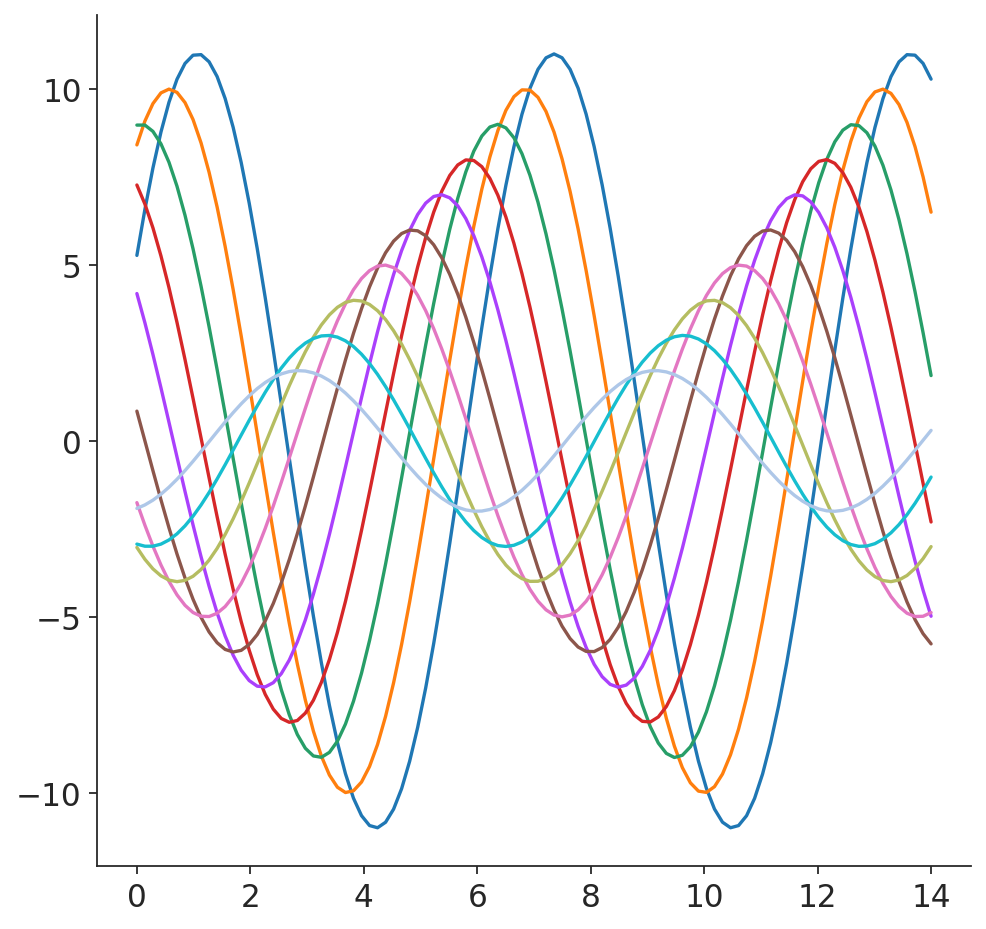

In [3]:
# sns.set_theme(style="ticks")
# sns.set_style("white")
sns.set_style("ticks") #{'axes.grid' : False}
# def sinplot(n=10, flip=1):
#     x = np.linspace(0, 14, 100)
#     for i in range(1, n + 1):
#         plt.plot(x, np.sin(x + i * .5) * (n + 2 - i) * flip)
# sinplot()
# sns.despine()

In [4]:
#### define color for factors
specie_color = {"mouse":"#00B0EB", "macaque":"#E2424A", "marmoset":"#F57F17", "human":"#2fd897"
               # "#BAE294"
               }
region_color = {"Hypothalamus":"#ffb300", "PFC": "#55c11a", "Visual": "#c88dc5", "Hippocampus": "#8ddbe2", "Motor":"#51a8b2", "Cerebellum":"#92bdf1"}
clu_color = {"EN": "#44c1f0", #"#f35177", 
             "IN":"#13a983", "MG":"#fcbad3", "OPC":"#f18800", "OD":"#ffa631", "AS":"#e8490f", "VAS":"#53ff8c", "EPTC":"#ffee6a"}

In [5]:
conv_tb = pl.read_csv("/gpfs/group/data_sci_group/weiwu_group/majianyun/data/Hypothalamus/scvi/region_comparison/conversion_table.ma.20241016.dedup.csv")
conv_human = conv_tb

### merge data 

In [7]:
marmoset_C4_10X = sc.read_h5ad("marmoset.2024.h5ad")

In [8]:
macaque_C4 = sc.read_h5ad("macaque.2024.h5ad")

In [9]:
mouse_10X = sc.read_h5ad("mouse.2024.h5ad")

In [10]:
human_10X = sc.read_h5ad("human.2024.h5ad")

In [11]:
pd.crosstab(marmoset_C4_10X.obs.region_name, marmoset_C4_10X.obs.seq_method)

In [12]:
adata = sc.concat([marmoset_C4_10X, macaque_C4, mouse_10X, human_10X], join="outer")

In [29]:
#### donor library info 
#### not adjust 
adata.obs.batch.value_counts()
#### donor info
adata.obs.donor.value_counts()
#### seq info
adata.obs.seq_method.value_counts()
#### specie info
adata.obs.specie.value_counts()

In [25]:
adata

### Start running

In [30]:
# filter gene with low count
sc.pp.filter_genes(adata, min_counts=10)
adata.layers["counts"] = adata.X.copy() # preserve counts
adata.layers["int_counts"] = np.rint(adata.layers["counts"]).astype(np.int64)
adata.layers["log"] = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4, layer="log")
sc.pp.log1p(adata, layer="log")
adata.raw = adata

In [32]:
scvi.model.SCVI.setup_anndata(
    adata,
    layer="int_counts",
    batch_key="specie",
    categorical_covariate_keys=["donor", "seq_method"]
)

In [ ]:
model = scvi.model.SCVI(adata, n_latent=100, dispersion="gene-batch", n_layers=3, n_hidden=1024)
model

In [ ]:
adata

In [ ]:
scvi.settings.seed = 42
model.train(use_gpu=True, max_epochs=250, batch_size=8192, early_stopping=True, 
                plan_kwargs=dict(n_epochs_kl_warmup=None, n_steps_kl_warmup=10))

In [37]:
adata.obsm["X_scVI"] = model.get_latent_representation()

In [38]:
adata.layers["scvi_normalized"] = model.get_normalized_expression(
    library_size=1e4
)

In [ ]:
pd.crosstab(adata.obs.specie[adata.obs.region_name == "Hypothalamus"], adata.obs.large_type[adata.obs.region_name == "Hypothalamus"]).iloc[:, 1:].apply(lambda x: x.div(x.sum()).mul(100), axis=1).astype(float).round(2)

### post integration processing & basic plot

In [39]:
adata.obsm["X_mde"] = scvi.model.utils.mde(adata.obsm["X_scVI"])

In [ ]:
sc.pl.embedding(
    adata,
    basis="X_mde",
    color=["specie", "region_name", "seq_method"] ,#+ markers ,
    frameon=False,
    ncols=1,
    size=1,
    # palette=Turbo256,
    legend_loc="right margin"
)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.leiden(adata, key_added="leiden_scVI", resolution=1)
sc.tl.paga(adata, groups="leiden_scVI")
sc.pl.paga(adata, node_size_scale=5, plot=False, groups="leiden_scVI")
sc.tl.umap(adata, min_dist=0.1, spread=1, init_pos="paga")

In [ ]:
sc.pl.umap(
    adata,
    color=["nFeature_RNA", "nCount_RNA", "seq_method"],
    frameon=False,
    size=1,
    ncols=1,
    legend_loc="right margin",
    legend_fontsize="medium"
)

In [ ]:
###### inpsection ratio of C4 & 10X data for each cluster
seq_ratio = pd.crosstab(adata.obs.leiden_scVI, adata.obs.seq_method)
(seq_ratio["C4"] / seq_ratio["10X"]).to_list()

### select problematic cluster 58
adata.obs["nine"] = (adata.obs.leiden_scVI == "58")

In [ ]:
# drop data to save
adata.obs.drop(columns="is_primary_data", inplace=True)
adata.write_h5ad("inte.20241028.h5ad")
model.save("inte.20241028.model.pkl")

In [6]:
adata = sc.read_h5ad("inte.20241028.h5ad")
adata.uns['log1p']["base"] = None

#### cell cluster

In [61]:
def sub_cluster(adata, cluster_label, cluster_name, new_label=None, 
                    method="leiden", reso=0.2, n_genes=50,
                    markers=None, model=None, return_sub=False):
    """
    run leiden in subcluster with unified adata object 
    """
    if new_label is None:
        new_label = cluster_label
    adata.obs[cluster_label] = adata.obs[cluster_label].astype(str)
    adata.obs[new_label] = adata.obs[cluster_label]
    sad = adata[adata.obs[cluster_label] == cluster_name, :] # sub adata
    
    if method == "leiden":
        sc.tl.leiden(sad, key_added=new_label, resolution=reso)
    ### marker inferences with scvi model
    if model is not None:
        adata.uns[cluster_name] = model.differential_expression(
            adata=sad,
            groupby=new_label,
            # weights="importance",
            filter_outlier_cells=True,
            batch_correction=True
        )
    
    ### plot umap result
    split_umap(sad, split_by="specie", color=new_label)
    if markers is not None:
        if markers == "model" and model is not None:
            markers = adata.uns[cluster_name].query(
                'group1 == "3" and bayes_factor > 3 and lfc_mean > 0 and non_zeros_proportion1 > 0.1'
            ).index.to_list()
        for i in markers:
            split_umap(sad, split_by="specie", color=i)
    sad.uns['log1p']["base"] = None
    sc.tl.rank_genes_groups(sad, new_label, layers="log", method='wilcoxon', tie_correct=True, key_added="sub_DE", n_genes=n_genes)
    rdf = sc.get.rank_genes_groups_df(sad, key="sub_DE", group=None)
    adata.obs.loc[sad.obs.index, new_label] = sad.obs[new_label].apply(lambda s: cluster_name + '_' + s).to_list()
    with pd.option_context('display.max_rows', 1000, 'display.max_columns', 10):
        display(rdf)
  
    if return_sub is True:
        return sad

In [62]:
def rename_clu(adata, cluster_label, oldn, newn):
    """
    rename cluster
    """
    if adata.obs[cluster_label].dtype == "category":
        adata.obs[cluster_label] = adata.obs[cluster_label].cat.rename_categories({oldn:newn})
    else:
        adata.obs.loc[adata.obs[cluster_label] == oldn, cluster_label] = newn

In [ ]:
sc.tl.rank_genes_groups(adata, 'leiden_scVI', use_raw=False,
                        method='wilcoxon', tie_correct=True, 
                        n_genes=5000, layer="log", key_added="cluster_rename")

In [ ]:
cdf = sc.get.rank_genes_groups_df(adata, key="cluster_rename", group=None)

In [ ]:
cdf[(cdf.logfoldchanges > 1.5) & (cdf.pvals_adj < 0.01)].to_csv("markers.clusters.202410.csv")

In [ ]:
cdf.to_csv("markers.clusters.202410.full.csv")

##### start annotation

In [8]:
# mtb = pl.read_csv("cluster.anno.202411.csv")
mtb = pl.read_csv("cluster.anno.202411.2025_rm_chat.csv")

In [9]:
mtb

In [10]:
adata.obs["ori_name"] = adata.obs_names

In [11]:
adata.obs_names_make_unique()

In [12]:
mdict = {str(c):t for c,t in zip(mtb.get_column("cluster"), mtb.get_column("large_type"))}
notedict = {str(c):t for c,t in zip(mtb.get_column("cluster"), mtb.get_column("note"))}

In [13]:
adata.obs["large_type"] = [mdict[i] for i in adata.obs.leiden_scVI]
adata.obs["note"] = [notedict[i] for i in adata.obs.leiden_scVI]

In [15]:
# adata.obs.to_csv("cluster_info.202411.csv")
adata.obs.to_csv("cluster_info.202411.2025.csv")

In [16]:
# adata.write_h5ad("inte.202411.anno.h5ad")
adata.write_h5ad("inte.202411.anno.2025.h5ad")

### read `adata` and filtering `UNK` cells

In [6]:
adata = sc.read_h5ad("inte.202411.anno.h5ad")
adata.uns['log1p']["base"] = None

In [17]:
# merge and filter UNK
adata_bak = adata
adata = adata_bak[adata_bak.obs.large_type != "UNK"].copy()

In [ ]:
# sc.pl.paga(adata, node_size_scale=5, plot=False, groups="leiden_scVI")
sc.tl.umap(adata, min_dist=0.1, spread=1, 
           # init_pos="paga", 
           random_state=42)

In [11]:
# adata.write_h5ad("inte.202411.anno.2025.filtered.h5ad")
adata.write_h5ad("inte.202411.anno.20250526.filtered.h5ad")

### read filtered `adata`

In [85]:
# adata = sc.read_h5ad("inte.202411.anno.2025.filtered.h5ad")
adata = sc.read_h5ad("inte.202411.anno.20250526.filtered.h5ad")

In [7]:
adata[adata.obs.large_type == "EPTC"].obs.region_name.value_counts()

region_name
Hypothalamus    1372
Hippocampus      794
Cerebellum       146
PFC               47
Motor             28
Visual            25
Name: count, dtype: int64

### UMAP plot

In [367]:
with plt.rc_context({"figure.figsize": (6.5, 5.5), "figure.dpi": (30)}):
    sc.pl.umap(
        adata,
        color=["specie"], #"batch",
        frameon=False,
        palette=specie_color,
        # palette={"M":"cyan", "F":"pink"},
        size=0.3,
        ncols=1,
        sort_order=False,
        legend_loc="right margin",
        legend_fontsize="small",
        title="Specie",
        save=".specie.svg"
    )

In [376]:
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (30)}):
    sc.set_figure_params(vector_friendly=False)
    fig, ax = plt.subplots()
    sc.pl.umap(
        adata,
        color=["specie"], #"batch",
        frameon=False,
        palette=specie_color,
        # palette={"M":"cyan", "F":"pink"},
        size=0.3,
        ncols=1,
        sort_order=False,
        legend_loc="none",
        legend_fontsize="small",
        ax=ax,
        show=False
    )
    ax.title.set_visible(False)
    plt.savefig("plots/UMAP.specie.svg")
    plt.show()
    sc.set_figure_params(vector_friendly=True)

In [369]:
with plt.rc_context({"figure.figsize": (6.5, 5.5), "figure.dpi": (30)}):
    sc.pl.umap(
        adata,
        color=["large_type"], #"batch",
        frameon=False,
        palette=clu_color,
        # palette={"M":"cyan", "F":"pink"},
        size=0.3,
        ncols=1,
        sort_order=False,
        legend_loc="right margin",
        legend_fontsize="small",
        title="Cell type",
        save=".cluster.svg"
    )

In [377]:
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (30)}):
    sc.set_figure_params(vector_friendly=False)
    fig, ax = plt.subplots()
    sc.pl.umap(
        adata,
        color=["large_type"], #"batch",
        frameon=False,
        palette=clu_color,
        # palette={"M":"cyan", "F":"pink"},
        size=0.3,
        ncols=1,
        sort_order=False,
        legend_loc="none",
        legend_fontsize="small",
        ax=ax,
        show=False
    )
    ax.title.set_visible(False)
    plt.savefig("plots/UMAP.large_type.svg")
    plt.show()
    sc.set_figure_params(vector_friendly=True)


In [371]:
with plt.rc_context({"figure.figsize": (6.5, 5.5), "figure.dpi": (30)}):
    sc.pl.umap(
        adata,
        color=["region_name"], #"batch",
        frameon=False,
        palette=region_color,
        alpha=0.7,
        # palette={"M":"cyan", "F":"pink"},
        size=0.8,
        ncols=1,
        sort_order=False,
        legend_loc="right margin",
        legend_fontsize="small",
        title="Region",
        save=".region.svg"
    )

In [378]:
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (30)}):
    sc.set_figure_params(vector_friendly=False)
    fig, ax = plt.subplots()
    sc.pl.umap(
        adata,
        color=["region_name"], #"batch",
        frameon=False,
        palette=region_color,
        # palette={"M":"cyan", "F":"pink"},
        size=0.3,
        ncols=1,
        sort_order=False,
        legend_loc="none",
        legend_fontsize="small",
        ax=ax,
        show=False
    )
    ax.title.set_visible(False)
    plt.savefig("plots/UMAP.region.svg")
    plt.show()
    sc.set_figure_params(vector_friendly=True)


In [14]:
with plt.rc_context({"figure.figsize": (6.5, 5.5), "figure.dpi": (90)}):
    sc.pl.umap(
        adata,
        color=["RYR2"], #"batch",
        frameon=False,
        palette=region_color,
        alpha=0.7,
        # palette={"M":"cyan", "F":"pink"},
        size=0.8,
        ncols=1,
        sort_order=False,
        layer="log",
        legend_loc="right margin",
        legend_fontsize="small",
        title="RYR2 expression",
        # save=".region.svg"
    )

#### draw marker expression and cell ratio

In [9]:
######## split to marker 
adata_en = adata[adata.obs.large_type == "EN"]

In [9]:
sc.tl.rank_genes_groups(adata_en, groupby="region_name", n_genes=100, method="wilcoxon", use_raw=False, layer="log", key_added="en")

adata_en_scaled = sc.pp.scale(adata_en, copy=True, layer="log")

In [10]:
mksdf = sc.get.rank_genes_groups_df(adata_en, key="en", group=None)
mksdf = mksdf.drop_duplicates(subset=["names"])

In [11]:
mksdf.to_csv("mksdf.ex.csv")

In [10]:
mksdf = pd.read_csv("mksdf.ex.csv")

In [12]:
len(mksdf["names"].to_list())

In [11]:
adata_en_scaled = sc.pp.scale(adata_en, copy=True, layer="log")
# 1. Split the object by group
groups = adata_en_scaled.obs['specie'].unique()
adata_en_scaleds_list = []

for group in groups:
    # Subset by group
    adata_en_scaled_sub = adata_en_scaled[adata_en_scaled.obs['specie'] == group].copy()
    
    # 2. Scale the specific layer for this subset
    # This scales genes across cells *within* this group only
    sc.pp.scale(adata_en_scaled_sub, layer='log', zero_center=True)
    
    # Rename the scaled layer for clarity (optional)
    adata_en_scaled_sub.layers['scaled_log_norm'] = adata_en_scaled_sub.layers['log']
    adata_en_scaleds_list.append(adata_en_scaled_sub)

# 3. Merge back (concatenate)
# Keep only necessary parts, or use outer join to ensure all genes are kept
adata_en_scaled_scaled = sc.concat(adata_en_scaleds_list, join="outer")

# The scaled data is now in 'scaled_log_norm'
print(adata_en_scaled_scaled.layers['scaled_log_norm'])

In [12]:
for i in mksdf[mksdf.group == "Hypothalamus"].names:
    if i in neuropeptides or i in tfs:
        print(i)

In [22]:
sc.pl.heatmap(
    adata_en_scaled_scaled, 
    mksdf["names"].to_list(), 
    groupby='region_name', 
    show_gene_labels=False, 
    swap_axes=True,
    cmap="bwr",
    layer="log",
    figsize=(20, 10),
    show=True,
    vmin=-3,
    vmax=3,
    save=".heatmap.en.svg")

In [ ]:
######## split to marker 
adata_in = adata[adata.obs.large_type == "IN"]

In [18]:
sc.tl.rank_genes_groups(adata_in, groupby="region_name", n_genes=100, method="wilcoxon", use_raw=False, layer="log", key_added="in")

adata_in_scaled = sc.pp.scale(adata_in, copy=True, layer="log")

In [19]:
mksidf = sc.get.rank_genes_groups_df(adata_in, key="in", group=None)
mksidf = mksidf.drop_duplicates(subset=["names"])

In [20]:
mksidf.to_csv("mksdf.in.csv")

In [ ]:
mksidf = pd.read_csv("mksdf.in.csv")

In [17]:
# for i in mksidf[mksidf.group == "Hypothalamus"].names:
#     if i in neuropeptides or i in tfs:
#         print(i)

In [ ]:
adata_in_scaled = sc.pp.scale(adata_in, copy=True, layer="log")
# 1. Split the object by group
groups = adata_in_scaled.obs['specie'].unique()
adata_in_scaleds_list = []

for group in groups:
    # Subset by group
    adata_in_scaled_sub = adata_in_scaled[adata_in_scaled.obs['specie'] == group].copy()
    
    # 2. Scale the specific layer for this subset
    # This scales genes across cells *within* this group only
    sc.pp.scale(adata_in_scaled_sub, layer='log', zero_center=True)
    
    # Rename the scaled layer for clarity (optional)
    adata_in_scaled_sub.layers['scaled_log_norm'] = adata_in_scaled_sub.layers['log']
    adata_in_scaleds_list.append(adata_in_scaled_sub)

# 3. Merge back (concatenate)
# Keep only necessary parts, or use outer join to ensure all genes are kept
adata_in_scaled_scaled = sc.concat(adata_in_scaleds_list, join="outer")

# The scaled data is now in 'scaled_log_norm'
print(adata_in_scaled_scaled.layers['scaled_log_norm'])

In [ ]:
sc.pl.heatmap(
    adata_in_scaled_scaled, 
    mksidf["names"].to_list(), 
    groupby='region_name', 
    show_gene_labels=False, 
    swap_axes=True,
    cmap=region_name,
    layer="log",
    figsize=(20, 10),
    show=True,
    vmin=-3,
    vmax=3,
    save=".heatmap.in.svg")

In [ ]:
#### enrich
###### EN
gene_set = ["GO_Biological_Process_2025", 
            "GO_Cellular_Component_2025", 
            "GO_Molecular_Function_2025", 
            "KEGG_2021_Human"]
gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                           "GO_Cellular_Component_2025": "chocolate",
                           "GO_Molecular_Function_2025": "turquoise",
                           "KEGG_2021_Human": "cornflowerblue"}
enr = gp.enrichr(gene_list=mksdf[mksdf.group == "Hypothalamus"].names, # or "./tests/data/gene_list.txt",
                 gene_sets=gene_set,
                 organism='Human', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                 background=adata.var_names.to_list(),
                 cutoff=1
                )
cat = len(enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique())
itemsize = sum(enr.results["Adjusted P-value"] < 0.05)
print(cat)
print(itemsize)
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (100)}):
    gp.barplot(enr.results,
                  column="Adjusted P-value",
                  group='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
                  size=5,
                  top_term=10,
                  figsize=(cat*2+0.5, itemsize/5+1.5),
                  color = [gene_set_color[i] for i in enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique()]
                 )
    plt.suptitle("Hypothalamus EN marker enrichment")
    plt.savefig("plots/HY.EN.enrichr.bar.svg")
    plt.show()
    enr.results.to_csv("HY.EN.enrichr.csv")

In [ ]:
#### enrich
###### IN
gene_set = ["GO_Biological_Process_2025", 
            "GO_Cellular_Component_2025", 
            "GO_Molecular_Function_2025", 
            "KEGG_2021_Human"]
gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                           "GO_Cellular_Component_2025": "chocolate",
                           "GO_Molecular_Function_2025": "turquoise",
                           "KEGG_2021_Human": "cornflowerblue"}
enr = gp.enrichr(gene_list=mksidf[mksidf.group == "Hypothalamus"].names, # or "./tests/data/gene_list.txt",
                 gene_sets=gene_set,
                 organism='Human', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                 background=adata.var_names.to_list(),
                 cutoff=1
                )
cat = len(enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique())
itemsize = sum(enr.results["Adjusted P-value"] < 0.05)
print(cat)
print(itemsize)
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (100)}):
    gp.barplot(enr.results,
                  column="Adjusted P-value",
                  group='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
                  size=5,
                  top_term=10,
                  figsize=(cat*2+0.5, itemsize/5+1.5),
                  # title = "HY human",
                  # xticklabels_rot=45, # rotate xtick labels
                  # show_ring=False, # set to False to revmove outer ring
                  # marker='o',
                  color = [gene_set_color[i] for i in enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique()]
                 )
    plt.suptitle("Hypothalamus IN marker enrichment")
    plt.savefig("plots/HY.IN.enrichr.bar.svg")
    plt.show()
    enr.results.to_csv("HY.IN.enrichr.csv")

In [67]:
##### load filtered terms
gene_set = ["GO_Biological_Process_2025", 
            "GO_Cellular_Component_2025", 
            "GO_Molecular_Function_2025", 
            "KEGG_2021_Human"]
gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                           "GO_Cellular_Component_2025": "chocolate",
                           "GO_Molecular_Function_2025": "turquoise",
                           "KEGG_2021_Human": "cornflowerblue"}
en_enrichf = pd.read_csv("/cluster/home/majianyun/data/Hypothalamus/scvi/region_comparison/enrichr_filtered/HY.EN.enrichr_Func_Filt.csv")
en_enrichf = en_enrichf[en_enrichf["P-value"] < 0.05]
cat = len(en_enrichf.Gene_set.unique())
itemsize = en_enrichf.shape[0]
fig = px.bar(en_enrichf[::-1],
              x="P-value",
              y="Term",
              color='Gene_set', # set x axis, so you could do a multi-sample/library comparsio
              # color = [gene_set_color[i] for i in en_enrichf.Gene_set.unique()], 
              color_discrete_map= gene_set_color,
              title="Hypothalamus EN marker enrichment",
              height=350,
              width=1000
             )
fig.show()
fig.write_image("plots/HY.EN.enrichr.bar.svg")
# plt.suptitle("Hypothalamus EN marker enrichment")
# plt.savefig("plots/HY.EN.enrichr.bar.svg")

In [63]:
##### load filtered terms
gene_set = ["GO_Biological_Process_2025", 
            "GO_Cellular_Component_2025", 
            "GO_Molecular_Function_2025", 
            "KEGG_2021_Human"]
gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                           "GO_Cellular_Component_2025": "chocolate",
                           "GO_Molecular_Function_2025": "turquoise",
                           "KEGG_2021_Human": "cornflowerblue"}
in_enrichf = pd.read_csv("/cluster/home/majianyun/data/Hypothalamus/scvi/region_comparison/enrichr_filtered/HY.IN.enrichr_Func_Filt.csv")
in_enrichf = in_enrichf[in_enrichf["P-value"] < 0.05]
cat = len(in_enrichf.Gene_set.unique())
itemsize = in_enrichf.shape[0]
fig = px.bar(in_enrichf,
              x="P-value",
              y="Term",
              color='Gene_set', # set x axis, so you could do a multi-sample/library comparsio
              # color = [gene_set_color[i] for i in en_enrichf.Gene_set.unique()], 
              title="Hypothalamus IN marker enrichment",
              color_discrete_map= gene_set_color,
              width=1000
             )
fig.show()
fig.write_image("plots/HY.IN.enrichr.bar.svg")
# plt.savefig("plots/HY.EN.enrichr.bar.svg")

#### draw cell type marker

In [ ]:
sc.tl.rank_genes_groups(adata, groupby="large_type", n_genes=10, method="wilcoxon", use_raw=False, layer="log", key_added="large_type")

In [ ]:
sc.tl.dendrogram(adata, groupby='large_type')

In [ ]:
sc.pl.rank_genes_groups_dotplot(adata, groupby="large_type",  key="large_type", use_raw=False, n_genes=10, standard_scale='var', save=".markers.svg")

#### draw cell type ratio

In [86]:
ct_count_sp = adata.obs.groupby(["large_type", 'region_name', "specie"]).size().reset_index(name='counts')
ct_count_sp["ratio_by_specie_and_region"] = ct_count_sp["counts"] / [ ct_count_sp[(ct_count_sp["large_type"] == lt) & (ct_count_sp["region_name"] == rn)].counts.sum() for lt,rn in zip(ct_count_sp["large_type"], ct_count_sp["region_name"]) ]
ct_count_sp.head()

/tmp/ipykernel_4031084/1427861446.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_count_sp = adata.obs.groupby(["large_type", 'region_name', "specie"]).size().reset_index(name='counts')


,large_type,region_name,specie,counts,ratio_by_specie_and_region
0,AS,Cerebellum,human,1841,0.274408
1,AS,Cerebellum,macaque,1820,0.271277
2,AS,Cerebellum,marmoset,2375,0.354002
3,AS,Cerebellum,mouse,673,0.100313
4,AS,Hippocampus,human,1583,0.130816


In [87]:
ct_count_sp_pt = ct_count_sp.pivot_table(index=["large_type", "region_name"], columns="specie", values='counts')
ct_count_sp_pt.reset_index()

/tmp/ipykernel_4031084/671957405.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  ct_count_sp_pt = ct_count_sp.pivot_table(index=["large_type", "region_name"], columns="specie", values='counts')


specie,large_type,region_name,human,macaque,marmoset,mouse
0,AS,Cerebellum,1841.0,1820.0,2375.0,673.0
1,AS,Hippocampus,1583.0,2664.0,3470.0,4384.0
2,AS,Hypothalamus,811.0,562.0,1988.0,2569.0
3,AS,Motor,307.0,2015.0,2652.0,1729.0
4,AS,PFC,453.0,2477.0,3458.0,3861.0
5,AS,Visual,505.0,2121.0,2017.0,1856.0
6,EN,Cerebellum,11981.0,13356.0,13384.0,14084.0
7,EN,Hippocampus,10522.0,13088.0,11044.0,6891.0
8,EN,Hypothalamus,8103.0,5026.0,3663.0,5289.0
9,EN,Motor,13063.0,11928.0,10777.0,15954.0


In [88]:
ct_res = ct_count_sp_pt.reset_index(drop=True)
ct_res = ct_res.div(ct_res.sum(axis=1), axis=0)
#### filter cell < 500
ct_res[(ct_count_sp_pt.sum(axis=1) < 1000).to_list()] = np.nan
ct_res

specie,human,macaque,marmoset,mouse
0,0.274408,0.271277,0.354002,0.100313
1,0.130816,0.220147,0.286753,0.362284
2,0.136762,0.094772,0.335245,0.433221
3,0.045800,0.300612,0.395644,0.257944
4,0.044199,0.241682,0.337399,0.376720
5,0.077704,0.326358,0.310355,0.285582
6,0.226891,0.252931,0.253461,0.266717
7,0.253268,0.315032,0.265832,0.165868
8,0.366967,0.227617,0.165889,0.239527
9,0.252562,0.230618,0.208364,0.308457


Plotting HeatmapAnnotations


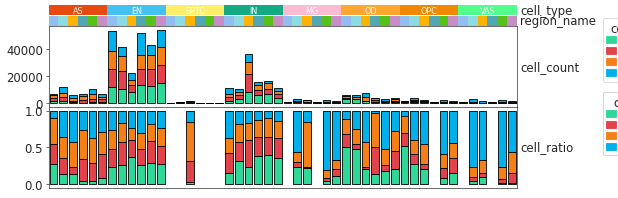

In [10]:
with plt.rc_context({"figure.figsize": (10, 4), "figure.dpi": (30), "lines.linewidth": 0.1}):
    col_ha = HeatmapAnnotation(cell_type=anno_simple(ct_count_sp_pt.index.get_level_values("large_type").to_series().reset_index(drop=True),add_text=True,legend=False,colors=clu_color, height=1), axis=1,
                            region_name=anno_simple(ct_count_sp_pt.index.get_level_values("region_name").to_series().reset_index(drop=True),add_text=False,legend=False,
                                                    colors=region_color, height=1),
                            # cell_ratio=anno_boxplot(ct_count_sp.pivot_table(index=["large_type", "region_name"], columns="specie", values='ratio_by_specie_and_region').reset_index(drop=True), cmap='turbo', height=5),
                            cell_count=anno_barplot(ct_count_sp_pt.reset_index(drop=True), colors=[specie_color[i] for i in ct_count_sp_pt.reset_index(drop=True).columns], height=8),
                            cell_ratio=anno_barplot(ct_res, colors=[specie_color[i] for i in ct_res.columns], height=8),
                           plot=True,legend=True,legend_gap=1)
    plt.savefig("plots/cluster.specie.ratio.svg")
    plt.show()

/tmp/ipykernel_4031084/1556518986.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_count_sp_hyinen = ct_count_sp_hyinen.sort_values("large_type").groupby(["region_name", "specie"], sort=False).agg({"counts": lambda v: v.tolist()[1] / v.tolist()[0]}) # IN?EN


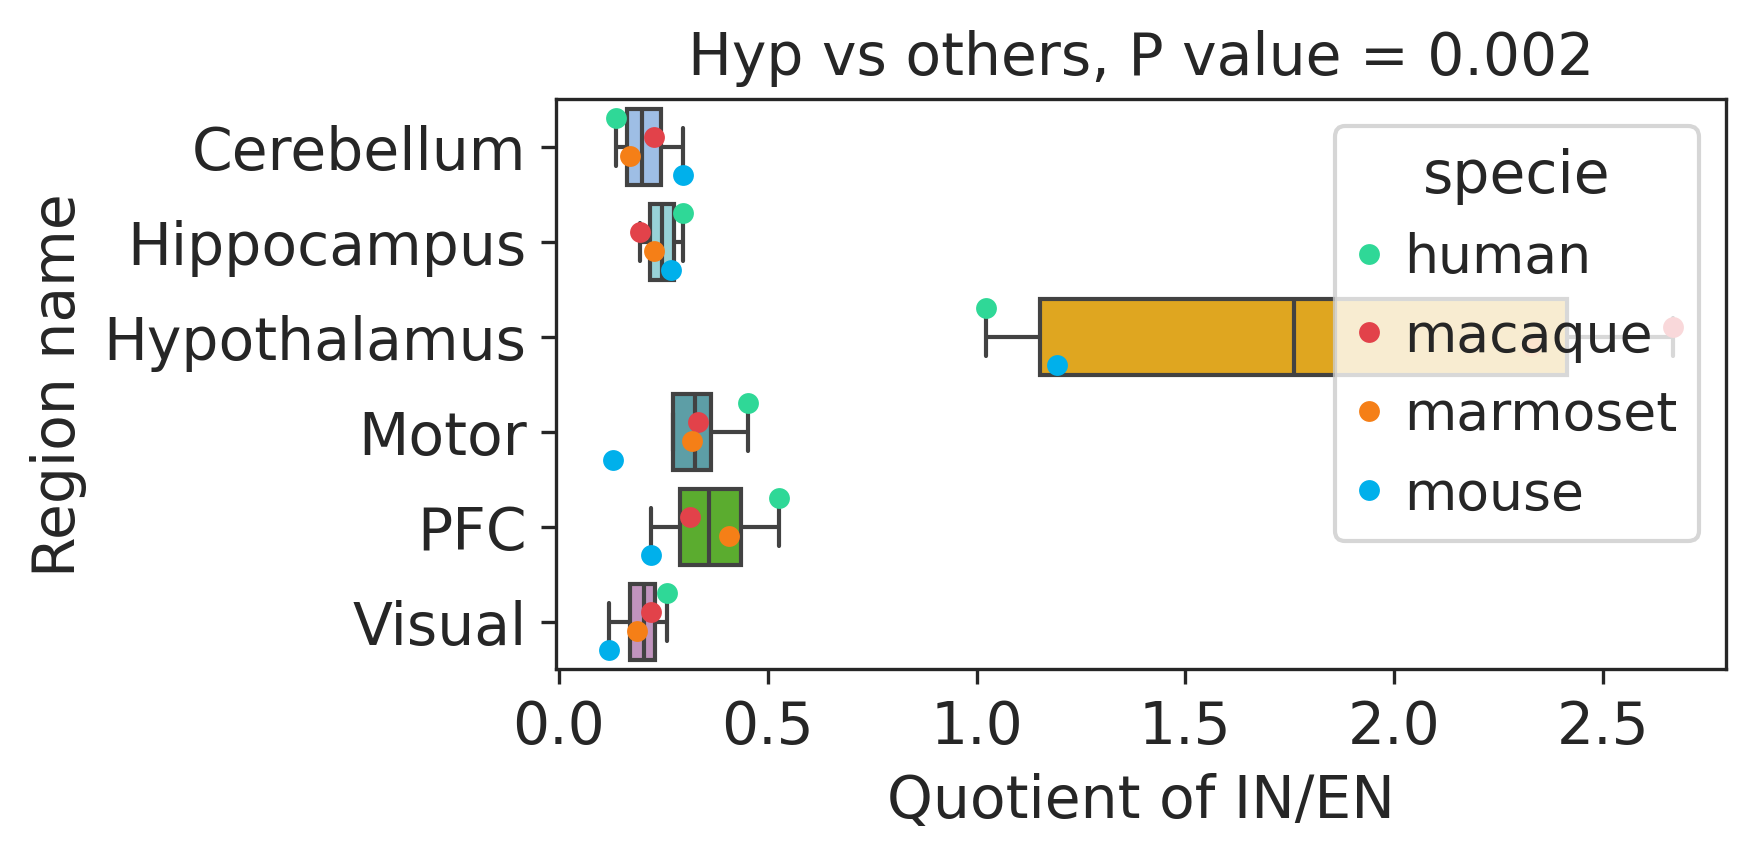

In [90]:
#### in/en RATIO quotient
ct_count_sp_hyinen = ct_count_sp[ct_count_sp.large_type.isin(["EN", "IN"])]
ct_count_sp_hyinen = ct_count_sp_hyinen.sort_values("large_type").groupby(["region_name", "specie"], sort=False).agg({"counts": lambda v: v.tolist()[1] / v.tolist()[0]}) # IN?EN

with plt.rc_context({"figure.figsize": (5, 2.5), "figure.dpi": (150)}):
    ax = sns.boxplot(data=ct_count_sp_hyinen, x="counts", y="region_name",
                    hue="region_name", palette=region_color, showfliers=False)
    sns.stripplot(data=ct_count_sp_hyinen, x="counts", y="region_name",
                hue="specie", palette=specie_color, dodge=True, ax=ax)
    plt.xlabel("Quotient of IN/EN") 
    plt.ylabel("Region name") 
    plt.title("Hyp vs others, P value = 0.002")
    plt.savefig("plots/quotient_in_en.replot.svg")
    plt.show()

In [91]:
ct_count_sp_hyinen.counts.reset_index()[ct_count_sp_hyinen.reset_index().region_name == "Hypothalamus"].counts

16    1.022461
17    2.327873
18    2.666335
19    1.193420
Name: counts, dtype: float64

In [92]:
ranksums(ct_count_sp_hyinen.counts.reset_index()[ct_count_sp_hyinen.reset_index().region_name == "Hypothalamus"].counts,
        ct_count_sp_hyinen.counts.reset_index()[ct_count_sp_hyinen.reset_index().region_name != "Hypothalamus"].counts)

RanksumsResult(statistic=np.float64(3.0983866769659336), pvalue=np.float64(0.0019457736937391486))

In [14]:
with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (100)}):
    sns.boxplot(adata.obs, y="nFeature_RNA", x="specie", hue="specie",
                  native_scale=True, whis=[0,100], palette=specie_color)
    plt.xticks(rotation=45)
    plt.xlabel("Specie") 
    plt.ylabel("Gene count per cell") 
    plt.savefig("plots/gene_count.boxplot.svg")
    plt.show()


#### leiden test

In [95]:
resos = [0.1, 0.25, 0.5, 0.75, 1, 2.5, 5, 7.5, 10, 12.5, 15, 17.5, 20]

In [15]:
for reso in resos:
    sc.tl.leiden(adata, key_added="leiden_scVI_" + str(reso), resolution=reso)

/tmp/ipykernel_3516144/1577895237.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, key_added="leiden_scVI_" + str(reso), resolution=reso)


In [16]:
def ent_scaled(adata, slot): # KL-divergence
    enttb = dict()
    enttb["cell_type"] = []
    enttb["entropy"] = [] 
    
    glb_distribution = adata.obs.specie.value_counts()[specie_color.keys()]
    # print(glb_distribution)
    for cell_type in adata.obs[slot].unique():
        crad = adata[(adata.obs[slot] == cell_type)]
        cradict = (crad.obs.specie.value_counts()).to_dict()
        etp = entropy([cradict[s]+1 if s in cradict.keys() else 1.0 for s in specie_color.keys()], 
                      qk=glb_distribution)
        print(cradict)
        print(etp)
        enttb["cell_type"].append(cell_type)
        enttb["entropy"].append(etp)
        
        
    enttb = pl.DataFrame(enttb)
    # enttb = enttb.with_columns(entropy_scaled=scale(enttb.get_column("entropy")))
    enttbdict = {i:j for i,j in zip(enttb.get_column("cell_type"), enttb.get_column("entropy"))}
    return(scale([enttbdict[i] for i in adata.obs[slot]]))

In [17]:
for reso in resos:
    adata.obs["entropy_scaled_"+str(reso)] = ent_scaled(adata, "leiden_scVI_" + str(reso))

{'marmoset': 13812, 'mouse': 13140, 'macaque': 13048, 'human': 11737}
0.0017331165184863613
{'human': 10900, 'macaque': 9205, 'marmoset': 7425, 'mouse': 5372}
0.032017686181822394
{'mouse': 13383, 'marmoset': 10739, 'macaque': 7019, 'human': 5470}
0.05800433712525849
{'human': 9270, 'marmoset': 8549, 'mouse': 8392, 'macaque': 4350}
0.03558491105414653
{'mouse': 5863, 'marmoset': 2253, 'macaque': 1011, 'human': 422}
0.37020159075603165
{'mouse': 2682, 'macaque': 1754, 'marmoset': 1275, 'human': 1098}
0.06193708734635314
{'macaque': 22842, 'marmoset': 19210, 'human': 12701, 'mouse': 11813}
0.037825205737647374
{'mouse': 4720, 'marmoset': 2974, 'human': 2811, 'macaque': 1865}
0.0539325224013389
{'mouse': 5148, 'marmoset': 2678, 'human': 2258, 'macaque': 761}
0.17386876837929585
{'human': 37139, 'macaque': 34104, 'marmoset': 32038, 'mouse': 30087}
0.0030328993487665594
{'human': 9344, 'macaque': 5471, 'marmoset': 4803, 'mouse': 3998}
0.05588483900383942
{'marmoset': 1051, 'macaque': 568, '

In [30]:
adata.write_h5ad("inte.2026.with_resos.h5ad")

In [93]:
adata = sc.read_h5ad("inte.2026.with_resos.h5ad")

In [96]:
### https://github.com/scverse/scanpy/issues/2333
def split_umap(adata, split_by, color, ncol=2, nrow=None, save=None, **kwargs):
    """
    split umap by facotr `split_by` then draw something with the same scale
    """
    if color not in adata.var.index and color not in adata.obs.columns:
        print(color + " not exist!")
        return()
    if (color not in adata.obs.columns):
        vmax = np.quantile(adata[:, adata.var.index == color].X.data, 0.99)
    else:
        vmax = None
        color_map = None
    
    categories = adata.obs[split_by].cat.categories
    if nrow is None:
        nrow = int(np.ceil(len(categories) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4*ncol, 4*nrow))
    fig.suptitle(color, fontsize=20)
    axs = axs.flatten()
    ### draw figure
    for i, cat in enumerate(categories):
        ax = axs[i]
        sc.pl.umap(adata[adata.obs[split_by] == cat], ax=ax, vmax=vmax, size=1,
            show=False, title=cat, color=color, legend_loc="on data", **kwargs)
    if save is not None:
        # if save == "output":
        save = "plots/" + color + ".svg"
        plt.savefig(fname=save, dpi=120)
    # plt.plot()
    return plt.tight_layout()

def split_umap_sp(col):
    split_umap(adata, split_by="specie", color=col, color_map="magma")

In [97]:
KLd_df = adata.obs[["entropy_scaled_"+str(reso) for reso in resos]+["region_name"]].melt(id_vars="region_name").rename(columns={"value":"scaled divergence across species", "variable":"resolution"})
# scaled KL divergence

In [98]:
KLd_df["resolution"] = [float(i.split('_')[-1]) for i in KLd_df["resolution"]]

In [99]:
cluster_count_dict = {}
for reso in resos:
    cluster_count_dict[reso] = len(adata.obs["entropy_scaled_"+str(reso)].unique())

In [100]:
KLd_df["cluster_count"] = [cluster_count_dict[reso]  for reso in KLd_df["resolution"]]

In [101]:
KLd_df["resolution(cluster number)"] = KLd_df["resolution"].astype(str) + ' (' + KLd_df["cluster_count"].astype(str) + ')'

In [103]:
KLd_df.region_name = KLd_df.region_name.astype("string")
cortex_b = KLd_df[KLd_df.region_name.isin(["Hypothalamus"])].groupby(["resolution", "region_name"])["scaled divergence across species"].mean().to_list()
cortex_u = KLd_df[~KLd_df.region_name.isin(["Hypothalamus"])].groupby(["resolution", "region_name"])["scaled divergence across species"].mean().to_list()
klp = ranksums(x=cortex_b, y=cortex_u).pvalue

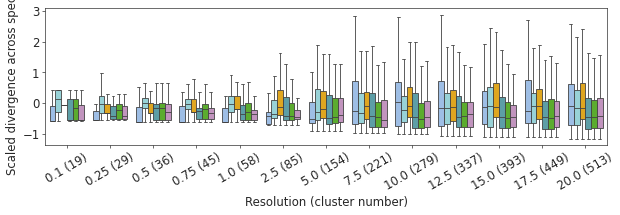

In [80]:
with plt.rc_context({"figure.figsize": (12, 3), "figure.dpi": (30)}):
    sns.boxplot(KLd_df,
        y="scaled divergence across species", x="resolution(cluster number)", hue="region_name",
        legend=False, #native_scale=True, notch=True,
        palette=region_color, showfliers=False
        # boxprops={"facecolor": (.3, .5, .7, .5)}
    )
    plt.xticks(rotation=30)
    plt.xlabel("Resolution (cluster number)") 
    plt.ylabel("Scaled divergence across species") 
    plt.savefig("plots/leiden.entropy.boxplot.svg", bbox_inches='tight')
    plt.show()


In [104]:
KLd_df_agg = KLd_df.groupby(["resolution", "region_name"])["scaled divergence across species"].mean().reset_index()


In [106]:
# test using per resolution
kruskal(*[group_df["scaled divergence across species"].to_list() for _, group_df in KLd_df_agg.groupby('region_name')])

KruskalResult(statistic=np.float64(46.28709459965552), pvalue=np.float64(7.93827660711045e-09))

In [108]:
from scikit_posthocs import posthoc_wilcoxon
phw = posthoc_wilcoxon(KLd_df_agg, val_col="scaled divergence across species", group_col="region_name", p_adjust="fdr_bh")
phw.to_csv("KLd.pval.csv")
phw

,Cerebellum,Hippocampus,Hypothalamus,Motor,PFC,Visual
Cerebellum,1.000000,0.304871,0.001221,0.315505,0.786865,0.327236
Hippocampus,0.304871,1.000000,0.004578,0.002616,0.000732,0.000732
Hypothalamus,0.001221,0.004578,1.000000,0.000732,0.000732,0.000732
Motor,0.315505,0.002616,0.000732,1.000000,0.164795,0.260343
PFC,0.786865,0.000732,0.000732,0.164795,1.000000,0.010173
Visual,0.327236,0.000732,0.000732,0.260343,0.010173,1.000000


In [ ]:
orip = []
for reso, gdf in KLd_df_agg.groupby("resolution"):
    cortex_b = KLd_df_agg[KLd_df_agg.region_name.isin(["Hypothalamus"])]["scaled divergence across species"].mean().to_list()
    cortex_u = KLd_df_agg[~KLd_df_agg.region_name.isin(["Hypothalamus"])]["scaled divergence across species"].mean().to_list()
    orip.append(ranksums(x=cortex_b, y=cortex_u).pvalue)
false_discovery_control(orip)

array([0.16927762, 0.37977547, 0.16927762, 0.16927762, 0.16927762,
       0.16927762, 0.16927762, 0.37977547, 0.16927762, 0.16927762,
       0.16927762, 0.16927762, 0.16927762])

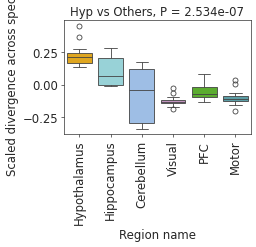

In [ ]:
region_color["Others"] = "#6f55ff"
with plt.rc_context({"figure.figsize": (4, 2.5), "figure.dpi": (30)}):
    sns.boxplot(KLd_df_agg,
        y="scaled divergence across species", x="region_name", hue="region_name",
        legend=False, #native_scale=True, notch=True,
        palette=region_color, order=["Hypothalamus", 'Hippocampus', 'Cerebellum', "Visual", "PFC", "Motor"]
        # boxprops={"facecolor": (.3, .5, .7, .5)}
    )
    plt.xticks(rotation=90)
    plt.xlabel("Region name") 
    plt.ylabel("Scaled divergence across species") 
    plt.title(f"Hyp vs Others, P = {klp:.3e}")
    plt.savefig("plots/leiden.entropy.boxplot.HY_vs_Others.svg", bbox_inches='tight')
    plt.show()


### downsample `adata` to `adata_ds`

In [7]:
adata_ds = adata

In [8]:
adata_ds = sc.pp.downsample_counts(adata_ds, counts_per_cell=5000, replace=True, copy=True)

In [9]:
adata_ds.layers["log"] = adata_ds.layers["counts"].copy()
sc.pp.normalize_total(adata_ds, target_sum=1e4, layer="log")
sc.pp.log1p(adata_ds, layer="log")

In [11]:
adata_ds_cell = subset_ad(adata_ds, cell_num=500, batch_name=["region_name", "specie", "large_type"])

/tmp/ipykernel_1310036/2817053077.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for k, v in adata.obs.groupby(batch_name).indices.items():


In [12]:
adata_ds_cell

View of AnnData object with n_obs × n_vars = 92500 × 14210
    obs: 'nCount_RNA', 'nFeature_RNA', 'specie', 'region_name', 'batch', 'donor', 'seq_method', 'cell_type', 'n_counts', 'doublet_score', 'predicted_doublet', 'CLUSTER', 'CLUSTER-SUBCLUSTER', 'organism_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'seq_pool', 'donor_id', 'structure', 'region', 'subregion', 'anatomical_name', 'age', 'slice', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_cells_by_counts', 'log1p_n_cells_by_counts', 'pct_counts_in_top_50_cells', 'pct_counts_in_top_100_cells', 'pct_counts_in_top_200_cells', 'pct_counts_in_top_500_cells', 'tissue_t

#### draw difference in region across specie (not merge cortex)

In [13]:
#### findmarkers by comparing region markers across different species split by clu
def get_rmks_as_clu(adata, clu, sp, r1, r2, pval=5e-2, logFC=1):
    sad = adata[(adata.obs["specie"] == sp) & (adata.obs["large_type"] == clu) & (adata.obs["region_name"].isin([r1, r2]))].copy()
    sc.tl.rank_genes_groups(sad, 'region_name',  layers="log", method='wilcoxon', tie_correct=True, key_added="rg_comp")
    sdf = sc.get.rank_genes_groups_df(sad, key="rg_comp", group=None)
    sdf = sdf[sdf["group"] == r1]
    sdf["group2"] = r2
    sdf["large_type"] = clu
    sdf["specie"] = sp
    sdf["direction"] = ["up" if i is True else "down" for i in sdf["logfoldchanges"] > 0 ]
    return(sdf[(sdf["pvals_adj"] < pval) & (sdf["logfoldchanges"].abs() > logFC)])

In [ ]:
###### run with equal number of cells (500) per cell type

clu_dict = {}
for clu in clu_color.keys():
    dfll = []
    if clu == "EPTC":
            continue
    for r1 in region_color.keys():
        # r1 = "Hypothalamus"
        for r2 in region_color.keys():
            if r1 == r2:
                continue
            dfl = list()
            for sp in specie_color.keys():
                print(clu,sp,r1,r2)
                dfl.append(get_rmks_as_clu(adata_ds_cell, clu, sp, r1, r2, logFC=0.5))
            dfll.append(pd.concat(dfl))
    clu_dict[clu] = pd.concat(dfll).groupby(
        ["group", "names", "direction", "large_type", "specie"]
    ).agg(
        {'logfoldchanges': 'mean', 'group2': 'count'}
    ).rename(columns={"group2": "region_count"})

In [34]:
pd.concat([gdf for ct,gdf in clu_dict.items()]).reset_index().query("(region_count == 5) and (direction == 'up')").drop(columns=["region_count", "direction"]).rename(
    columns={'group': 'Brain region', "names": "Gene name", "large_type": "Cell type", "specie": "Species", "logfoldchanges": "Mean logfoldchanges"}).to_csv("RSM.csv", index=False)

##### normal draw

In [227]:
clu_count = []
for clu_name,clu_df in clu_dict.items():
    clu_mpd = clu_df[clu_df['region_count'] == (len(region_color)-1)].reset_index() # multiple pandas
    C
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    print(dfc_conserved_up)
    for region in adata.obs.region_name.unique():
        figure_df = clu_mpd.merge(clu_mpd.value_counts(["names", "direction", "group"]).reset_index()).query('count == 1 and group == "{}"'.format3(region))
        figure_df["Specie"] = figure_df["specie"]
        fig = px.pie(figure_df.set_index("specie"), color="Specie",
                     names='Specie', title=clu_mpd.large_type[0] + ' ' + region, color_discrete_map=specie_color)
        fig.show()
        fig.write_image("plots/specie_region_enrich/" + clu_name + '.' + region + ".svg")

clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[clu_count_df.large_type.isin(["EN", "IN"])],
             facet_col="large_type", y="group", x="gene_count", 
             color="specie_count", title="Region markers of neuron cells", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=3).update_layout(
    autosize=False,
    width=500,
    height=300).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))



fig.show()
fig.write_image("plots/region_marker.3_cortex.neuron.svg")

In [251]:
clu_count_df["gene_count"] = clu_count_df["gene_count"].astype(int)

In [279]:
############ draw clu dict heatmap
clu_count_df
with plt.rc_context({"figure.figsize": (5, 5), "figure.dpi": (80)}):
    heat = sns.heatmap(clu_count_df[clu_count_df.large_type == "EN"].pivot(index=["group"], columns=["specie_count"],values="gene_count"),
                cmap="plasma", robust=True, annot=True, fmt="3g", square=True, vmax=3000, vmin=0)
    heat.figure.suptitle('EN') 
    plt.savefig("plots/RSMs.EN.heatmap.svg")
    plt.show()

In [226]:
clu_count = []
for clu_name,clu_df in clu_dict.items():
    clu_mpd = clu_df[clu_df['region_count'] == (len(region_color)-1)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    
clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[[ not i for i in clu_count_df.large_type.isin(["EC", "FB", "EN", "IN"])]], 
             facet_col="large_type", y="group", x="gene_count", 
             color="specie_count", title="Region markers of non-neuron cells", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=5).update_layout(
    autosize=False,
    width=800,
    height=300).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))



fig.show()
fig.write_image("plots/region_marker.3_cortex.non_neuron.svg")

In [280]:
############ draw clu dict heatmap
clu_count_df
with plt.rc_context({"figure.figsize": (5, 5), "figure.dpi": (80)}):
    heat = sns.heatmap(clu_count_df[clu_count_df.large_type == "IN"].pivot(index=["group"], columns=["specie_count"],values="gene_count"),
                cmap="plasma", robust=True, annot=True, fmt="3g", square=True, vmax=3000, vmin=0)
    heat.figure.suptitle('IN') 
    plt.savefig("plots/RSMs.IN.heatmap.svg")
    plt.show()

In [113]:
clu_count = []
for clu_name,clu_df in clu_dict.items():
    clu_mpd = clu_df[clu_df['region_count'] == (len(region_color)-1)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    
clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[[ not i for i in clu_count_df.large_type.isin(["EC", "FB"])]], 
             facet_col="large_type", x="group", y="gene_count", 
             color="specie_count", title="Region markers", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=2).update_layout(
    autosize=False,
    width=500,
    height=700).update_xaxes(
    tickangle=45
).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))



fig.show()
fig.write_image("plots/region_marker.3_cortex.svg")

In [128]:
dfc_conserved_up

In [ ]:
clu_list = []

if not os.path.exists("primate_enrich"):
    os.makedirs("primate_enrich")
#### `conserved up` means up-regulation compared to all other regions
for clu_name,clu_df in clu_dict.items():
    clu_mpd = clu_df[clu_df['region_count'] == (len(region_color)-1)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up_dd = dfc_conserved_up.drop_duplicates(subset=['names', 'direction', 'large_type', 'group']).set_index(['names', 'group'])
    rn_dict = {}
    for gn,region in dfc_conserved_up.groupby(['names', 'group']):
        rn_dict[gn] = region.specie.to_list() # species of region 
    for r in specie_color.keys():
        dfc_conserved_up_dd[r] = False
    for gn, region in rn_dict.items():
        for s in specie_color.keys():
            if s in region:
                dfc_conserved_up_dd.loc[gn, s] = True
    dfc_conserved_up_dd = dfc_conserved_up_dd.reset_index()
    for i in specie_color.keys():
        if i == list(specie_color.keys())[0]:
            dfc_conserved_up_dd = dfc_conserved_up_dd.set_index(i)
        else:
            dfc_conserved_up_dd = dfc_conserved_up_dd.set_index(i, append=True)
    upset = UpSet(dfc_conserved_up_dd, show_counts=True, #orientation="vertical",
              intersection_plot_elements=0)
    upset.add_stacked_bars(by="group", colors=region_color,
                           title="specie markers", elements=10)
    upset.plot()
    plt.suptitle(clu_name)
    plt.savefig("plots/upset." + clu_name + ".region_markers.svg")
    plt.show()
    
    hy_cup = dfc_conserved_up_dd[dfc_conserved_up_dd.group == "Hypothalamus"]
    
    #### append for the step followed
    #### only human hypothalamus up-regulated gene
    if (False, True, True, True) in hy_cup.index:
        hyh_genes_primate = hy_cup.loc[False, True, True, True].names.unique().tolist()
        hy_cup.to_csv("primate_enrich/primate_high_in_HY." + hy_cup.large_type.to_list()[0] + ".mks.csv")
        clu_list.append(hy_cup.loc[False, True, True, True])
    else:
        continue
    
    hyh_genes = hy_cup.loc[False, False, False, True].names.unique().tolist()
    
        
    
    gene_size = len(hyh_genes)
    gene_set = ["GO_Biological_Process_2025", 
                "GO_Cellular_Component_2025", 
                "GO_Molecular_Function_2025", 
                "KEGG_2021_Human",
               ]
    gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                               "GO_Cellular_Component_2025": "chocolate",
                               "GO_Molecular_Function_2025": "turquoise",
                               "KEGG_2021_Human": "cornflowerblue",
                     }

    enr = gp.enrichr(gene_list=hyh_genes, # or "./tests/data/gene_list.txt",
                     gene_sets=gene_set,
                     organism='Human', # don't forget to set organism to the one you desired! e.g. Yeast
                     outdir=None, # don't write to disk
                     background=adata.var_names.to_list(),
                     cutoff=1
                    )
    enr.results.to_csv("primate_enrich/primate_high_in_HY." + hy_cup.large_type.to_list()[0] + ".enrich.csv")
    print(enr.results)
    if (enr.results["Adjusted P-value"] < 0.05).eq(True).any():
        cat = len(enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique())
        itemsize = sum(enr.results["Adjusted P-value"] < 0.05)
        print(cat)
        print(itemsize)
        gp.barplot(enr.results,
                      column="Adjusted P-value",
                      group='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
                      size=5,
                      top_term=10,
                      figsize=(cat*4+0.5, itemsize/5+1.5),
                      color = [gene_set_color[i] for i in enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique()]
                     )
        plt.suptitle(clu_name + ' (' + str(gene_size) + ')')
        plt.savefig("plots/HY.region_marker.enrich.{}.svg".format(clu_name), bbox_inches='tight')
        plt.show()

In [64]:
def plot_ct(adata, ct, genes, save=None):
    sad = adata[adata.obs.large_type == ct]
    sad.obs["exp"] = sad.layers['log'][:, sad.var_names.to_list().index(genes)].toarray()
    with plt.rc_context({"figure.figsize": (2, 4), "figure.dpi": (30)}):
        sns.catplot(
            data=sad.obs, x="region_name", y="exp", hue="specie", row="specie", 
            kind="violin", height=2, palette = specie_color, bw_method="scott", #cut=0,
            width=1, cut=0, density_norm='width', inner=None, sharey=False, common_norm = False,
            aspect=4#, hue_norm=True
        )
        plt.xticks(rotation=30)
        if save is not None:
            plt.savefig(save)
        plt.show()    
def plot_region(adata, region, genes):
    sad = adata[adata.obs.region_name == region]
    sad.obs["exp"] = sad.layers['log'][:, sad.var_names.to_list().index(genes)].toarray()
    with plt.rc_context({"figure.figsize": (2, 4), "figure.dpi": (30)}):
        sns.catplot(
            data=sad.obs, x="large_type", y="exp", hue="specie", row="specie",
            kind="violin", height=2, palette = specie_color, bw_method="scott", #cut=0, 
            width=1, cut=0, density_norm='width', inner=None, sharey=False,  common_norm = False,
            aspect=4#, hue_norm=True
        )
        plt.show()    

In [65]:
with plt.rc_context({"figure.figsize": (2, 3), "figure.dpi": (30)}):
    plot_ct(adata, "MG", "HTR2C", save="primate_enrich/primate_specific.hy.MG.HTR2C.svg") 
    plt.show()
with plt.rc_context({"figure.figsize": (2, 3), "figure.dpi": (30)}):
    plot_ct(adata, "MG", "HTR2B", save="primate_enrich/primate_specific.hy.MG.HTR2B.svg") 
    plt.show()
with plt.rc_context({"figure.figsize": (2, 3), "figure.dpi": (30)}):
    plot_ct(adata, "AS", "HSPB8", save="primate_enrich/primate_specific.hy.AS.HSPB8.svg") 
    plt.show()


##### merge cortex data

In [181]:
cortex_region = ["Visual", "PFC", "Motor"]

In [182]:
adata_ds_cortex = adata_ds_cell[adata_ds_cell.obs.region_name.isin(cortex_region)]

In [183]:
adata_ds_subcortex = adata_ds_cell[[ not i for i in adata_ds_cell.obs.region_name.isin(cortex_region)]]

In [184]:
sc.pp.subsample(adata_ds_cortex, fraction=1/3, random_state=42)

In [185]:
adata_ds_cortex.obs.region_name = "Cortex"

In [186]:
adata_ds_dsc = sc.concat([adata_ds_cortex, adata_ds_subcortex], join="outer") # downsample cortex

In [187]:
adata_ds_cortex.obs.region_name.value_counts()

In [188]:
subcortex_region = set(region_color.keys()) - set(cortex_region)

In [190]:
clu_dict_dsc = {}
for clu in clu_color.keys():
    dfll = []
    if clu == "EPTC" or clu == "FB" or clu == "EC":
            continue
    for r1 in list(subcortex_region) + ["Cortex"]:
        # r1 = "Hypothalamus"
        for r2 in list(subcortex_region) + ["Cortex"]:
            if r1 == r2:
                continue
            dfl = list()
            for sp in specie_color.keys():
                print(clu,sp,r1,r2)
                dfl.append(get_rmks_as_clu(adata_ds_dsc, clu, sp, r1, r2, logFC=1))
            dfll.append(pd.concat(dfl))

    clu_dict_dsc[clu] = pd.concat(dfll).groupby(
        ["group", "names", "direction", "large_type", "specie"]
    ).agg(
        {'logfoldchanges': 'mean', 'group2': 'count'}
    ).rename(columns={"group2": "region_count"})

In [192]:
clu_count = []
for clu_name,clu_df in clu_dict_dsc.items():
    clu_mpd = clu_df[clu_df['region_count'] == len(cortex_region)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    
clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[[ i for i in clu_count_df.large_type.isin(["IN", "EN"])]], 
             facet_col="large_type", y="group", x="gene_count", 
             color="specie_count", title="region markers", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=3).update_layout(
    autosize=False,
    width=500,
    height=300).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

fig.show()
fig.write_image("plots/region_marker.merge_cortex.neuron.svg")

In [193]:
clu_count = []
for clu_name,clu_df in clu_dict_dsc.items():
    clu_mpd = clu_df[clu_df['region_count'] == len(cortex_region)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    
clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[[ not i for i in clu_count_df.large_type.isin(["EC", "FB", "EN", "IN"])]], 
             facet_col="large_type", y="group", x="gene_count", 
             color="specie_count", title="region markers", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=4).update_layout(
    autosize=False,
    width=700,
    height=300).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))


fig.show()
fig.write_image("plots/region_marker.merge_cortex.non_neuron.svg")

In [197]:
clu_count = []
for clu_name,clu_df in clu_dict_dsc.items():
    clu_mpd = clu_df[clu_df['region_count'] == len(cortex_region)].reset_index() # multiple pandas
    dfc_conserved_up = clu_mpd[clu_mpd["direction"] == "up"]
    dfc_conserved_up = dfc_conserved_up.groupby(["group", "names", "large_type"]).size().reset_index().rename(columns={0:"specie_count"}).groupby(["group", "specie_count", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
    clu_count.append(dfc_conserved_up)
    
clu_count_df = pd.concat(clu_count)
clu_count_df["specie_count"] = clu_count_df["specie_count"].astype(str)
fig = px.bar(clu_count_df[[ not i for i in clu_count_df.large_type.isin(["EC", "FB"])]], 
             facet_col="large_type", y="group", x="gene_count", 
             color="specie_count", title="region markers", color_discrete_map={i:j for i,j in zip([str(i) for i in range(1,5)], Burg_4.hex_colors)},
             facet_col_wrap=7).update_layout(
    autosize=False,
    width=1200,
    height=300).update_xaxes(
    tickangle=45
)

fig.show()
fig.write_image("plots/region_marker.merge_cortex.svg")

### specie comparison
- treat two NHP as duplication
- logFC == 0.5 test

In [37]:
def DE_cross_specie(ad, s1, s2, clu, region, pval=5e-2, logFC=0.5):
    sc.tl.rank_genes_groups(ad, 'specie', layers="log", method='wilcoxon', tie_correct=True, key_added="specie_DE")
    sdf = sc.get.rank_genes_groups_df(ad, key="specie_DE", group=None)
    
    sdf = sdf[sdf["group"] == s1]
    sdf["specie2"] = s2
    sdf["large_type"] = clu
    sdf["region"] = region
    sdf["direction"] = ["up" if i is True else "down" for i in sdf["logfoldchanges"] > 0 ]
    sdf.loc[(sdf["pvals_adj"] > pval) | (sdf["logfoldchanges"].abs() < logFC), "direction"] = "NoSig"
    
    return(sdf)

##### get mouse-macaque mouse-marmoset macaque-human marmoset-human marker

In [39]:
sdfl = []
for clu in list(clu_color.keys())[:-1]:
    for region in region_color.keys():
        region_adds = adata_ds_cell[(adata_ds_cell.obs.region_name == region) & (adata_ds_cell.obs.large_type == clu)]
        ### comparison 4
        sdfl.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["mouse", "macaque"])], "macaque", "mouse", clu, region, logFC=0.5))
        sdfl.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["mouse", "marmoset"])], "marmoset", "mouse", clu, region, logFC=0.5))
        sdfl.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["human", "macaque"])], "human", "macaque", clu, region, logFC=0.5))
        sdfl.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["human", "marmoset"])], "human", "marmoset", clu, region, logFC=0.5))

In [ ]:
#### count between NHP & between human and mouse
sdfl2 = []
for clu in list(clu_color.keys())[:-1]:
    for region in region_color.keys():
        region_adds = adata_ds_cell[(adata_ds_cell.obs.region_name == region) & (adata_ds_cell.obs.large_type == clu)]
        ### comparison 4
        sdfl2.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["mouse", "human"])], "human", "mouse", clu, region, logFC=0.5))
        sdfl2.append(DE_cross_specie(region_adds[region_adds.obs.specie.isin(["macaque", "marmoset"])], "macaque", "marmoset", clu, region, logFC=0.5))

In [144]:
sdfl2_count = pd.concat(sdfl2).query('direction != "NoSig"').groupby(["group", "specie2", "large_type", "region"])["pvals"].count().reset_index()

In [145]:
sdfl2_count["comparison"] = sdfl2_count["group"] + ' VS ' + sdfl2_count["specie2"]

In [146]:
sdfl2_count

,group,specie2,large_type,region,pvals,comparison
0,human,mouse,AS,Cerebellum,9161,human VS mouse
1,human,mouse,AS,Hippocampus,8268,human VS mouse
2,human,mouse,AS,Hypothalamus,8137,human VS mouse
3,human,mouse,AS,Motor,9838,human VS mouse
4,human,mouse,AS,PFC,8476,human VS mouse
...,...,...,...,...,...,...
79,macaque,marmoset,VAS,Hippocampus,6277,macaque VS marmoset
80,macaque,marmoset,VAS,Hypothalamus,8120,macaque VS marmoset
81,macaque,marmoset,VAS,Motor,7118,macaque VS marmoset
82,macaque,marmoset,VAS,PFC,7030,macaque VS marmoset


In [168]:
fig = px.bar(sdfl2_count, 
             facet_col="large_type", x="pvals", y="comparison",
             color="region", title="DEGs count between specie", color_discrete_map=region_color, 
            facet_col_wrap=1).update_layout(
    autosize=False,
    width=600,
    height=600).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))


fig.show()
fig.write_image("plots/DEGs.count.introduction.svg")

In [157]:
asdf = pd.concat(sdfl)

In [7]:
asdf["trend_category"] = asdf.group + '_' + asdf.specie2

##### Split genes into 3 category 

In [8]:
def determine_trend_by_p_logfc(p, logfc, p_cut=0.05, logfc_cut=0.5):
    if p > p_cut or abs(logfc) < logfc_cut:
        return("NoSig")
    elif logfc > 0:
        return("up")
    else:
        return("down")

def determine_trend_category(trend):
    return({"macaque_mouse":"mac_mou_trend",
     "marmoset_mouse":"mar_mou_trend",
     "human_macaque":"hum_mac_trend",
     "human_marmoset":"hum_mar_trend"}[trend])

In [9]:
asdf["trend"] = [determine_trend_by_p_logfc(p, logfc) for p,logfc in zip(asdf["pvals_adj"], asdf["logfoldchanges"])]
asdf["trend_category"] = [determine_trend_category(t) for t in asdf["trend_category"]]
asdf

,Unnamed: 0,group,names,scores,logfoldchanges,pvals,pvals_adj,specie2,large_type,region,direction,trend_category,trend
0,0,macaque,STRC,22.449850,10.263243,1.284033e-111,1.401390e-110,mouse,EN,Hypothalamus,up,mac_mou_trend,up
1,1,macaque,TUSC3,22.395674,32.921310,4.336988e-111,4.675918e-110,mouse,EN,Hypothalamus,up,mac_mou_trend,up
2,2,macaque,PTPRG,22.368238,39.105080,8.024427e-111,8.592849e-110,mouse,EN,Hypothalamus,up,mac_mou_trend,up
3,3,macaque,IQCA1,19.443266,8.849602,3.323252e-84,2.062158e-83,mouse,EN,Hypothalamus,up,mac_mou_trend,up
4,4,macaque,FBXL13,18.279537,7.373615,1.204433e-74,6.278429e-74,mouse,EN,Hypothalamus,up,mac_mou_trend,up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387275,14205,human,FGF14,-21.802300,-10.855538,2.206474e-105,4.479143e-102,marmoset,VAS,Cerebellum,down,hum_mar_trend,down
2387276,14206,human,SNAP25,-21.915558,-7.016521,1.846215e-106,4.372454e-103,marmoset,VAS,Cerebellum,down,hum_mar_trend,down
2387277,14207,human,GRIK2,-22.138270,-11.843709,1.353334e-108,3.846174e-105,marmoset,VAS,Cerebellum,down,hum_mar_trend,down
2387278,14208,human,RBFOX1,-23.208649,-18.402618,3.723958e-119,2.645872e-115,marmoset,VAS,Cerebellum,down,hum_mar_trend,down


##### Combine records with the same gene, region and large type

In [10]:
asdf_uniq = asdf.pivot(index=["names", "region", "large_type"], columns=["trend_category"], values="trend").reset_index()
asdf_uniq

trend_category,names,region,large_type,hum_mac_trend,hum_mar_trend,mac_mou_trend,mar_mou_trend
0,A1BG,Cerebellum,AS,up,NoSig,NoSig,NoSig
1,A1BG,Cerebellum,EN,up,up,NoSig,NoSig
2,A1BG,Cerebellum,IN,up,up,NoSig,NoSig
3,A1BG,Cerebellum,MG,up,NoSig,NoSig,up
4,A1BG,Cerebellum,OD,up,up,NoSig,NoSig
...,...,...,...,...,...,...,...
596815,ZZZ3,Visual,IN,NoSig,NoSig,down,down
596816,ZZZ3,Visual,MG,down,down,up,up
596817,ZZZ3,Visual,OD,up,up,down,NoSig
596818,ZZZ3,Visual,OPC,up,up,down,down


##### Define gene trend in terms of evolution

In [17]:
def tread_eva(i, j):
    if (i != "NoSig") and (j != "NoSig"):
        if i == j  == "up":
            return("up")
        elif i == j  == "down":
            return("down")
        else:
            return("divergent")
    else:
        return("NoSig")

In [18]:
asdf_uniq["mac_all_trend"] = [tread_eva(i,j) for i,j in zip(asdf_uniq["mac_mou_trend"], asdf_uniq["hum_mac_trend"])]
asdf_uniq["mar_all_trend"] = [tread_eva(i,j) for i,j in zip(asdf_uniq["mar_mou_trend"], asdf_uniq["hum_mar_trend"])]
asdf_uniq["mac_mar_all_trend"] = [
    "consistent" if i in ["up", "down"] and j in ["up", "down"] and k in ["up", "down"] and l in ["up", "down"] and i==k and j==l
    else "divergent" if i in ["up", "down"] and j in ["up", "down"] and k in ["up", "down"] and l in ["up", "down"] and (i!=k or j!=l) 
    else "non-significant change" 
    for i,j,k,l in zip(asdf_uniq["mac_mou_trend"], asdf_uniq["hum_mac_trend"], asdf_uniq["mar_mou_trend"], asdf_uniq["hum_mar_trend"])
]
asdf_uniq["mac_mar_convergent_type"] = [
    "consistent up" if m == "consistent" and i == j == k == l == "up"
    else "consistent down" if m == "consistent" and i == j == k == l == "down"
    else "consistent variable change across NHP" if m == "consistent" and not (i == j == k == l)
    else pd.NA
    for i,j,k,l,m in zip(asdf_uniq["mac_mou_trend"], asdf_uniq["hum_mac_trend"], asdf_uniq["mar_mou_trend"], asdf_uniq["hum_mar_trend"], asdf_uniq["mac_mar_all_trend"])
]
### replace divergent trend
asdf_uniq["mac_mar_divergent_type"] = [
    "complete divergent" if m == "divergent" and i != k and j != l
    else "NHP-mouse divergent" if m == "divergent" and i != k
    else "human-NHP divergent" if m == "divergent" and j != l
    else pd.NA
    for i,j,k,l,m in zip(asdf_uniq["mac_mou_trend"], asdf_uniq["hum_mac_trend"], asdf_uniq["mar_mou_trend"], asdf_uniq["hum_mar_trend"], asdf_uniq["mac_mar_all_trend"])
]

In [14]:
asdf_uniq_for_save = asdf_uniq.copy()

##### make dimension reduction

In [28]:
asdf_uniq_save_final = asdf_uniq.drop(columns=["Unnamed: 0", "mac_all_trend", "mar_all_trend", "mac_mar_convergent_type"]).rename(
    columns={"names": "Gene name", "region": "Brain region", "large_type":"Cell type", 
                "hum_mac_trend": "Change of macaque to human",
                "hum_mar_trend": "Change of marmoset to human",
                "mac_mou_trend": "Change of mouse to macaque",
                "mar_mou_trend": "Change of mouse to marmoset",
                "mac_mar_all_trend": "Evolution change by NHP",
                "mac_mar_divergent_type": "NDM type"})#.to_csv("specie_markers.500.refine.csv", index=False)
asdf_uniq_save_final[asdf_uniq_save_final["Evolution change by NHP"].isin(["consistent", "divergent"])].to_csv("specie_markers.500.refine.csv", index=False)

In [ ]:
asdf_uniq[asdf_uniq.mac_mar_divergent_type == "human-NHP divergent"]

In [125]:
import umap

In [128]:
import sklearn

In [417]:
aggad = sc.get.aggregate(
    adata, layer="scvi_normalized",
    by=["region_name", "specie", "large_type"], func=["mean", "count_nonzero"]
)

In [418]:
aggad = sc.pp.scale(aggad, copy=True, layer="mean")

In [419]:
aggadtp = aggad.transpose()

In [421]:
embedding = umap.UMAP(random_state=42).fit_transform(aggadtp.layers["mean"])

In [423]:
max_obs = aggadtp.var.iloc[aggadtp.layers["mean"].argmax(axis=1)]

In [424]:
max_obs.index = aggadtp.obs.index

In [425]:
aggadtp.obs = pd.concat([aggadtp.obs, max_obs], axis=1)

In [426]:
aggadtp.obs["UMAP0"] = embedding[:,0]
aggadtp.obs["UMAP1"] = embedding[:,1]

##### calculate divergent / convergent ratio of genes

In [32]:
asdf_uniq_dc_ratio = asdf_uniq.reset_index().groupby(["region", "mac_mar_all_trend", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
asdf_uniq_dc_ratio = asdf_uniq_dc_ratio.pivot_table(index=["region", "large_type"], columns="mac_mar_all_trend", values='gene_count').reset_index()
asdf_uniq_dc_ratio["Divergent/consistent gene ratio"] = asdf_uniq_dc_ratio["divergent"] / asdf_uniq_dc_ratio["consistent"] 
asdf_uniq_dc_ratio_pu = asdf_uniq_dc_ratio.pivot_table(index=["region"], columns="large_type", values='Divergent/consistent gene ratio').reset_index().set_index("region")

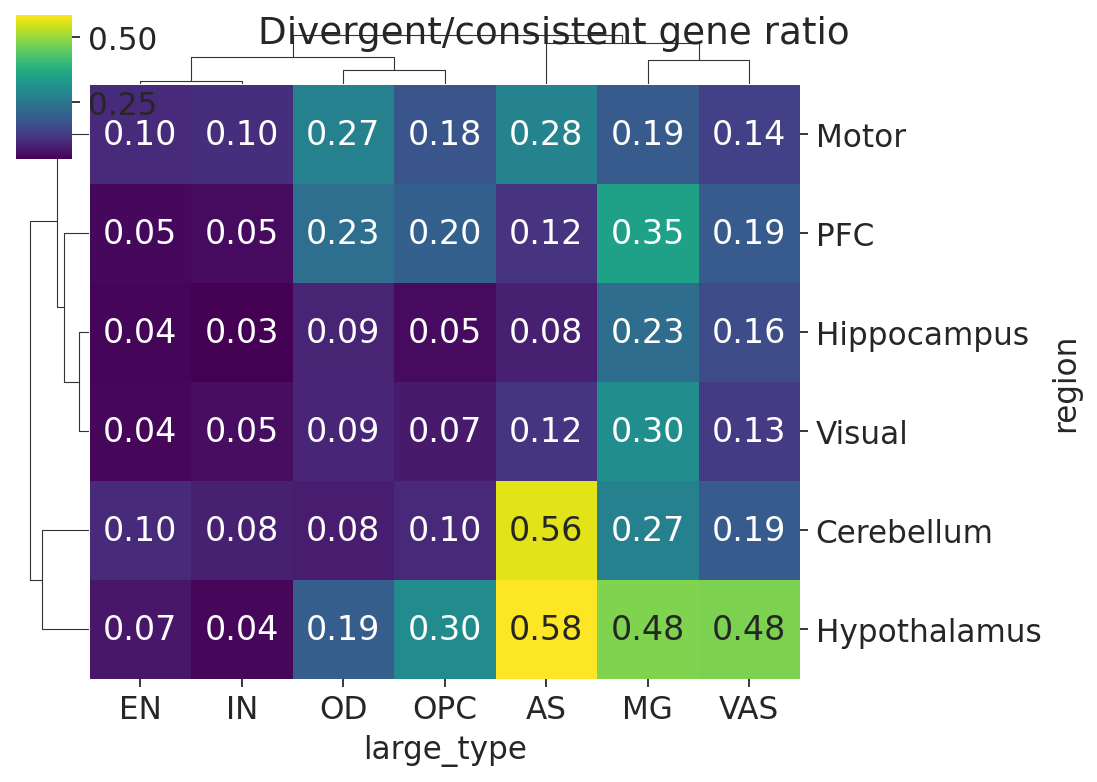

In [33]:
with plt.rc_context({"figure.figsize": (5, 5), "figure.dpi": (80)}):
    heat = sns.clustermap(asdf_uniq_dc_ratio_pu,
                cmap="viridis", figsize=(7,5), dendrogram_ratio=0.08, annot_kws={"size": 15}, fmt='.2f', annot=True)
    heat.fig.suptitle('Divergent/consistent gene ratio') 
    plt.savefig("plots/evo_path.divergence.heatmap.svg")
    plt.show()

In [34]:
neuron_dcgr = asdf_uniq_dc_ratio_pu[['EN', 'IN']].values.ravel()
non_neuron_dcgr = asdf_uniq_dc_ratio_pu.drop(columns=['EN', 'IN']).values.ravel()

In [35]:
hy_dcgr = asdf_uniq_dc_ratio_pu.loc["Hypothalamus"].drop(columns=['EN', 'IN']).values.ravel()
motor_dcgr = asdf_uniq_dc_ratio_pu.loc["Motor"].drop(columns=['EN', 'IN']).values.ravel()
pfc_dcgr = asdf_uniq_dc_ratio_pu.loc["PFC"].drop(columns=['EN', 'IN']).values.ravel()
visual_dcgr = asdf_uniq_dc_ratio_pu.loc["Visual"].drop(columns=['EN', 'IN']).values.ravel()
hippo_dcgr = asdf_uniq_dc_ratio_pu.loc["Hippocampus"].drop(columns=['EN', 'IN']).values.ravel()
cerebellum_dcgr = asdf_uniq_dc_ratio_pu.loc["Cerebellum"].drop(columns=['EN', 'IN']).values.ravel()
other_dcgr = asdf_uniq_dc_ratio_pu.loc[asdf_uniq_dc_ratio_pu.index != 'Hypothalamus'].drop(columns=['EN', 'IN']).values.ravel()

In [36]:
ranksums(neuron_dcgr, non_neuron_dcgr)

RanksumsResult(statistic=np.float64(-4.259872254881239), pvalue=np.float64(2.0454377320509104e-05))

In [37]:
ranksums(hy_dcgr, motor_dcgr)

RanksumsResult(statistic=np.float64(1.0860901604998978), pvalue=np.float64(0.27743910513984715))

In [38]:
ranksums(hy_dcgr, pfc_dcgr)

RanksumsResult(statistic=np.float64(1.0860901604998978), pvalue=np.float64(0.27743910513984715))

In [39]:
ranksums(hy_dcgr, visual_dcgr)

RanksumsResult(statistic=np.float64(1.4694160994998617), pvalue=np.float64(0.14171996321059))

In [40]:
ranksums(hy_dcgr, hippo_dcgr)

RanksumsResult(statistic=np.float64(1.8527420384998257), pvalue=np.float64(0.06391934147515746))

In [41]:
ranksums(hy_dcgr, cerebellum_dcgr)

RanksumsResult(statistic=np.float64(0.7027642214999339), pvalue=np.float64(0.48220269762779056))

In [42]:
ranksums(hy_dcgr, other_dcgr)

RanksumsResult(statistic=np.float64(1.116813649304452), pvalue=np.float64(0.2640740115600386))

In [43]:
asdf_uniq

,Unnamed: 0,names,region,large_type,hum_mac_trend,hum_mar_trend,mac_mou_trend,mar_mou_trend,mac_all_trend,mar_all_trend,mac_mar_all_trend,mac_mar_convergent_type,mac_mar_divergent_type
0,0,A1BG,Cerebellum,AS,up,NoSig,NoSig,NoSig,NoSig,NoSig,Non-significant change,NaN,NaN
1,1,A1BG,Cerebellum,EN,up,up,NoSig,NoSig,NoSig,NoSig,Non-significant change,NaN,NaN
2,2,A1BG,Cerebellum,IN,up,up,NoSig,NoSig,NoSig,NoSig,Non-significant change,NaN,NaN
3,3,A1BG,Cerebellum,MG,up,NoSig,NoSig,up,NoSig,NoSig,Non-significant change,NaN,NaN
4,4,A1BG,Cerebellum,OD,up,up,NoSig,NoSig,NoSig,NoSig,Non-significant change,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
596815,596815,ZZZ3,Visual,IN,NoSig,NoSig,down,down,NoSig,NoSig,Non-significant change,NaN,NaN
596816,596816,ZZZ3,Visual,MG,down,down,up,up,divergent,divergent,consistent,consistent variable change across NHP,NaN
596817,596817,ZZZ3,Visual,OD,up,up,down,NoSig,divergent,NoSig,Non-significant change,NaN,NaN
596818,596818,ZZZ3,Visual,OPC,up,up,down,down,divergent,divergent,consistent,consistent variable change across NHP,NaN


In [44]:
asdf_uniq_dc_ratio_ori = asdf_uniq.reset_index().groupby(["region", "mac_mar_all_trend", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
with plt.rc_context({"figure.figsize": (2, 2), "figure.dpi": (50)}):
    
    fig = px.bar(asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["EN", "IN", "OD", "OPC", "MG", "AS", "VAS"])], range_y=[5000, 15000],
                 facet_col="large_type", x="region", y="gene_count", color="mac_mar_all_trend", title="All gene category", facet_col_wrap=7).update_layout(
        autosize=True,
        width=1400,
        height=380,
    ).update_yaxes(
    tickmode='array',
    tickvals=[5000, 10000, 15000]).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])).update_xaxes(tickangle= 25)  

    fig.show()
    fig.write_image("plots/specie_marker.category.svg")

In [45]:
asdf_uniq_dc_ratio_oris = asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["OD", "OPC", "MG", "AS", "VAS"])] # non-neu

In [46]:
hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_all_trend == "divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values
non_hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_all_trend == "divergent")  & (asdf_uniq_dc_ratio_oris.region != "Hypothalamus")].gene_count.values.ravel()

In [47]:
ranksums(hy_div_count_arr, non_hy_div_count_arr)

RanksumsResult(statistic=np.float64(3.1441497132539404), pvalue=np.float64(0.0016657019746286977))

##### trend gene inspection

In [48]:
trendtb = asdf_uniq
trendtb = trendtb[trendtb["mac_mar_all_trend"] != ("Non-significant change")]

########## split consistent & divergent group
cst = trendtb[trendtb["mac_mar_all_trend"] == "consistent"]
dvg = trendtb[trendtb["mac_mar_all_trend"] == "divergent"]

In [320]:
region_color_grey = {}
for i,_ in region_color.items():
    region_color_grey[i] = "grey"
region_color_grey["Hypothalamus"] = region_color["Hypothalamus"]

In [328]:
for i in clu_color.keys():
    demodf = cst[cst["large_type"] == i]
    demodff = demodf.groupby(["names"]).first().reset_index()
    for j in region_color.keys():
        demodff[j] = demodf["region"].str.contains(j).groupby(demodf['names']).sum().gt(0).to_list()
    demodff = demodff.set_index(list(region_color.keys()))    
    # print(demodff)

    upset = UpSet(demodff, show_counts=True, #orientation="vertical",
              sort_by = "cardinality", max_subset_rank=12,
              intersection_plot_elements=0)
    
    upset.add_stacked_bars(by="region", colors=region_color_grey,
                           title="specie markers", elements=10)
    upset.style_categories(#present="Hypothalamus", absent=["PFC", "Visual", "Motor", "Hippocampus", "Cerebellum"], 
                           #facecolor=region_color["Hypothalamus"]
                            categories="Hypothalamus", bar_facecolor=region_color["Hypothalamus"]#, shading_facecolor=region_color["Hypothalamus"]
    )
    upset.style_subsets(present="Hypothalamus", #absent=["PFC", "Visual", "Motor", "Hippocampus", "Cerebellum"], 
                        facecolor=region_color["Hypothalamus"])
    upset.plot()
    plt.suptitle(i)
    plt.savefig("plots/upset." + i + ".evo_consistent.svg")
    plt.show()



In [329]:
for i in clu_color.keys():
    demodf = dvg[dvg["large_type"] == i]
    demodff = demodf.groupby(["names"]).first().reset_index()
    for j in region_color.keys():
        demodff[j] = demodf["region"].str.contains(j).groupby(demodf['names']).sum().gt(0).to_list()
    demodff = demodff.set_index(list(region_color.keys()))    
    # print(demodff)

    upset = UpSet(demodff, show_counts=True, #orientation="vertical",
              sort_by = "cardinality", max_subset_rank=12,
              intersection_plot_elements=0)

    upset.add_stacked_bars(by="region", colors=region_color_grey,
                           title="specie markers", elements=10)
    upset.style_categories(#present="Hypothalamus", absent=["PFC", "Visual", "Motor", "Hippocampus", "Cerebellum"], 
                           #facecolor=region_color["Hypothalamus"]
                            categories="Hypothalamus", bar_facecolor=region_color["Hypothalamus"]#, shading_facecolor=region_color["Hypothalamus"]
    )
    upset.style_subsets(present="Hypothalamus", #absent=["PFC", "Visual", "Motor", "Hippocampus", "Cerebellum"], 
                        facecolor=region_color["Hypothalamus"])

    upset.plot()
    plt.suptitle(i)
    plt.savefig("plots/upset." + i + ".evo_divergent.svg")
    plt.show()



In [140]:
for i in region_color.keys():
    demodf = cst[cst["region"] == i]
    demodff = demodf.groupby(["names"]).first().reset_index()
    for j in demodff["large_type"].unique():
        demodff[j] = demodf["large_type"].str.contains(j).groupby(demodf['names']).sum().gt(0).to_list()
    demodff = demodff.set_index(list(demodff["large_type"].unique()))    
    # print(demodff)

    upset = UpSet(demodff, show_counts=True, #orientation="vertical",
              sort_by = "cardinality", max_subset_rank=12)
    upset.plot()
    plt.suptitle(i)
    plt.savefig("plots/upset." + i + ".evo_consistent.svg")
    plt.show()



In [141]:
for i in region_color.keys():
    demodf = dvg[dvg["region"] == i]
    demodff = demodf.groupby(["names"]).first().reset_index()
    for j in demodff["large_type"].unique():
        demodff[j] = demodf["large_type"].str.contains(j).groupby(demodf['names']).sum().gt(0).to_list()
    demodff = demodff.set_index(list(demodff["large_type"].unique()))

    upset = UpSet(demodff, show_counts=True, #orientation="vertical",
              sort_by = "cardinality", max_subset_rank=12)
    upset.plot()
    plt.suptitle(i)
    plt.savefig("plots/upset." + i + ".evo_divergent.svg")
    plt.show()



In [95]:
asdf_uniq_dc_ratio_ori = asdf_uniq.reset_index().groupby(["region", "mac_mar_convergent_type", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
with plt.rc_context({"figure.figsize": (2, 2), "figure.dpi": (50)}):
    
    fig = px.bar(asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["EN", "IN", "OD", "OPC", "MG", "AS", "VAS"])], 
                 facet_col="large_type", y="region", x="gene_count", color="mac_mar_convergent_type", title="NHP markers", facet_col_wrap=7).update_layout(
        autosize=False,
        width=1400,
        height=380,
    ).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])).update_xaxes(tickangle= 25)  

    fig.show()
    fig.write_image("plots/specie_marker.category.consistent.svg")

In [49]:
asdf_uniq_dc_ratio_ori = asdf_uniq.reset_index().groupby(["region", "mac_mar_divergent_type", "large_type"]).size().reset_index().rename(columns={0:"gene_count"})
with plt.rc_context({"figure.figsize": (2, 2), "figure.dpi": (50)}):
    
    fig = px.bar(asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["EN", "IN", "OD", "OPC", "MG", "AS", "VAS"])], 
                 facet_col="large_type", y="region", x="gene_count", color="mac_mar_divergent_type", 
                 title="Divergent gene count", facet_col_wrap=7).update_layout(
        autosize=False,
        width=1400,
        height=380,
    ).for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])).update_xaxes(tickangle= 25)  

    fig.show()
    fig.write_image("plots/specie_marker.category.divergent.svg")

In [70]:
asdf_uniq_dc_ratio_oris = asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["OD", "OPC", "MG", "AS", "VAS"])]

In [71]:
hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "human-NHP divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values
non_hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "human-NHP divergent")  & (asdf_uniq_dc_ratio_oris.region != "Hypothalamus")].gene_count.values.ravel()

In [72]:
hn_p = ranksums(hy_div_count_arr, non_hy_div_count_arr).pvalue
hn_p

np.float64(0.005876230561718315)

In [73]:
asdf_uniq_dc_ratio_oris = asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["OD", "OPC", "MG", "AS", "VAS"])]

In [74]:
hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "NHP-mouse divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values
non_hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "NHP-mouse divergent")  & (asdf_uniq_dc_ratio_oris.region != "Hypothalamus")].gene_count.values.ravel()

In [75]:
nm_p = ranksums(hy_div_count_arr, non_hy_div_count_arr).pvalue
nm_p

np.float64(0.00290890658105115)

In [76]:
asdf_uniq_dc_ratio_oris = asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["OD", "OPC", "MG", "AS", "VAS"])]

In [77]:
hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "complete divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values
non_hy_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "complete divergent")  & (asdf_uniq_dc_ratio_oris.region != "Hypothalamus")].gene_count.values.ravel()

In [78]:
c_p = ranksums(hy_div_count_arr, non_hy_div_count_arr).pvalue
c_p

np.float64(0.002011689856093678)

In [79]:
asdf_uniq_dc_ratio_oris = asdf_uniq_dc_ratio_ori[asdf_uniq_dc_ratio_ori.large_type.isin(["OD", "OPC", "MG", "AS", "VAS"])]

In [80]:
hn_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "human-NHP divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values
nm_div_count_arr = asdf_uniq_dc_ratio_oris[(asdf_uniq_dc_ratio_oris.mac_mar_divergent_type == "NHP-mouse divergent")  & (asdf_uniq_dc_ratio_oris.region == "Hypothalamus")].gene_count.values.ravel()

In [81]:
ranksums(hn_div_count_arr, nm_div_count_arr)

RanksumsResult(statistic=np.float64(2.6111648393354674), pvalue=np.float64(0.009023438818080326))

In [84]:
false_discovery_control([hn_p, nm_p, c_p], method="bh")

array([0.00587623, 0.00436336, 0.00436336])

In [179]:
##### enrich HY divergent AS marker by different categroy
for j in asdf_uniq.large_type.unique():
    as_dvg = asdf_uniq[(asdf_uniq.region == "Hypothalamus") & (asdf_uniq.large_type == j) & (asdf_uniq.mac_mar_all_trend == "divergent")]

    print(as_dvg.mac_mar_divergent_type.value_counts())

    for i in as_dvg.mac_mar_divergent_type.unique():
        hyh_genes = as_dvg[as_dvg.mac_mar_divergent_type == i].names.to_list()
        # print(hyh_genes)
        gene_size = len(hyh_genes)
        gene_set = ["GO_Biological_Process_2025", 
                    "GO_Cellular_Component_2025", 
                    "GO_Molecular_Function_2025", 
                    "KEGG_2021_Human"
                   ]
        gene_set_color = {'GO_Biological_Process_2025': 'salmon', 
                                   "GO_Cellular_Component_2025": "chocolate",
                                   "GO_Molecular_Function_2025": "turquoise",
                                   "KEGG_2021_Human": "cornflowerblue"
                         }
        enr = gp.enrichr(gene_list=hyh_genes, # or "./tests/data/gene_list.txt",
                         gene_sets=gene_set,
                         organism='Human', # don't forget to set organism to the one you desired! e.g. Yeast
                         outdir=None, # don't write to disk
                         background=adata.var_names.to_list(),
                         cutoff=1
                        )
        # print(enr.results)
        if (enr.results["Adjusted P-value"] < 0.05).eq(True).any():
            cat = len(enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique())
            itemsize = sum(enr.results["Adjusted P-value"] < 0.05)
            print(cat)
            print(itemsize)
            gp.barplot(enr.results,
                          column="Adjusted P-value",
                          group='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
                          size=5,
                          top_term=10,
                          figsize=(cat+0.5, itemsize/5+1.5),
                          color = [gene_set_color[i] for i in enr.results.Gene_set[enr.results["Adjusted P-value"] < 0.05].unique()]
                         )
            plt.suptitle(j + " - " + i + ' (' + str(gene_size) + ')')
            plt.savefig("plots/HY.evo_marker.enrich.{}.svg".format(j + " - " + i), bbox_inches='tight')
            plt.show()

##### correlation

In [14]:
def plot_cor_origin_log_mean(ad_nps, gvar, sn, ltn, postfix):
    if "dendrogram_" + gvar  in ad_nps.uns_keys():
        del ad_nps.uns["dendrogram_"+ gvar]

    with plt.rc_context({"figure.figsize": (5, 5), "figure.dpi": (40)}):
        adsc = sc.get.aggregate(ad_nps, by=["region_name"], func='mean', obsm="X_pca")
        admat = adsc.layers["mean"] # aggregated data matrix
        admatc = np.corrcoef(admat) # mat correlation
        sns.heatmap(admatc, annot=True, fmt=".1f", vmin=-1, vmax=1, cmap="coolwarm", square=True, cbar=True,
                    xticklabels=adsc.obs.region_name, yticklabels=adsc.obs.region_name)
        plt.savefig("plots/cor." + gvar + "." + postfix + ".sumup.svg", bbox_inches='tight')
        plt.show()
    adsc = ad_nps[ad_nps.obs.large_type.isin(["EN", "IN", "OD", "OPC", "MG", "AS", "VAS"])]
    ss = adsc.obs[sn].unique()
    llt = adsc.obs[ltn].unique()
    adsc = sc.get.aggregate(adsc, by=["large_type", "specie", "region_name"], func='mean', obsm="X_pca")
    admat = adsc.layers["mean"] # aggregated data matrix
    admatc = np.corrcoef(admat) # mat correlation
    
    # Create figure with subplots for each condition
    with plt.rc_context({"figure.figsize": (len(ss), len(llt)), "figure.dpi": (100)}):
        fig, axes = plt.subplots(nrows=len(ss), ncols=len(llt), figsize=(len(llt)*1.3, len(ss)*1.5), sharex=False, sharey=False)
        for i,s in enumerate(ss):
            for j,lt in enumerate(llt):
                print([s, lt])
                admatc_sub = admatc[(adsc.obs[ltn] == lt) & (adsc.obs[sn] == s)][..., (adsc.obs[ltn] == lt) & (adsc.obs[sn] == s)]
                sns.heatmap(admatc_sub, annot=False, vmin=-1, vmax=1, cmap="coolwarm", square=True, cbar=False, ax=axes[i][j])
                axes[i][j].tick_params(left = False, right = False , labelleft = False , 
                        labelbottom = False, bottom = False) 
                axes[i][j].set(xticklabels=[])
                axes[i][j].set(yticklabels=[])
                if i == 0:
                    axes[i][j].set_title(lt)
                if j == 0:
                    axes[i][j].set_ylabel(s)
        fig.tight_layout()

        plt.savefig("plots/cor." + gvar + "." + postfix + ".svg", bbox_inches='tight')
        plt.show()

In [15]:
def plot_cor_origin_log_mean_sep(ad_nps, gvar, sn, ltn, postfix):
    if "dendrogram_" + gvar  in ad_nps.uns_keys():
        del ad_nps.uns["dendrogram_"+ gvar]

        
    with plt.rc_context({"figure.figsize": (5, 5), "figure.dpi": (40)}):
        adsc = sc.get.aggregate(ad_nps, by=["region_name"], func='mean', obsm="X_pca")
        admat = adsc.layers["mean"] # aggregated data matrix
        admatc = np.corrcoef(admat) # mat correlation
        sns.heatmap(admatc, annot=True, fmt=".1f", vmin=-1, vmax=1, cmap="coolwarm", square=True, cbar=True,
                    xticklabels=adsc.obs.region_name, yticklabels=adsc.obs.region_name)
        plt.savefig("plots/cor." + gvar + "." + postfix + ".specie_PCA.sumup.svg", bbox_inches='tight')
        plt.show()
    
    adsc = ad_nps[ad_nps.obs.large_type.isin(["EN", "IN", "AS", "OD", "OPC", "MG", "VAS"])]
    ss = adsc.obs[sn].unique()
    llt = adsc.obs[ltn].unique()
    
    # Create figure with subplots for each condition
    with plt.rc_context({"figure.figsize": (len(ss), len(llt)), "figure.dpi": (100)}):
        fig, axes = plt.subplots(nrows=len(ss), ncols=len(llt), figsize=(len(llt)*1.3, len(ss)*1.5), sharex=False, sharey=False)
        for i,s in enumerate(ss):
            for j,lt in enumerate(llt):
                print([s, lt])
                adsc_sub = adsc[(adsc.obs[ltn] == lt) & (adsc.obs[sn] == s)].copy()
                sc.tl.pca(adsc_sub, n_comps=50, use_highly_variable=False)
                adsc_sub = sc.get.aggregate(adsc_sub, by=["large_type", "specie", "region_name"], func='mean', obsm="X_pca")
                admat = adsc_sub.layers["mean"] # aggregated data matrix
                admatc = np.corrcoef(admat) # mat correlation
    
                sns.heatmap(admatc, annot=False, vmin=-1, vmax=1, cmap="coolwarm", square=True, cbar=False, ax=axes[i][j])
                axes[i][j].tick_params(left = False, right = False , labelleft = False , 
                        labelbottom = False, bottom = False) 
                axes[i][j].set(xticklabels=[])
                axes[i][j].set(yticklabels=[])
                if i == 0:
                    axes[i][j].set_title(lt)
                if j == 0:
                    axes[i][j].set_ylabel(s)
        fig.tight_layout()

        plt.savefig("plots/cor." + gvar + "." + postfix + ".specie_PCA.svg", bbox_inches='tight')
        plt.show()

In [16]:
plt.show()

In [17]:
r="region_name"
s="specie"
t="large_type"
mode="all"
ad_nps = adata.copy()
ad_nps.X = ad_nps.layers['log']
sc.tl.pca(ad_nps, n_comps=50, use_highly_variable=False)
plot_cor_origin_log_mean_sep(ad_nps, r, s, t, mode)
plot_cor_origin_log_mean(ad_nps, r, s, t, mode)


In [ ]:
plt.show()
mode="all"

r = "region_name"
s = "specie"
t = "large_type"
if mode == "all":
    ad_nps = adata.copy()
else:
    ad_nps = adata[:, nps].copy()

ad_nps.X = ad_nps.layers["counts"]
sc.pp.normalize_total(ad_nps, target_sum=10000, inplace=True)
sc.pp.log1p(ad_nps)

# plot cor
plot_cor_origin_log_mean(ad_nps, r, s, t, mode)


In [105]:
def plot_ct(adata, ct, genes):
    sad = adata[adata.obs.large_type == ct]
    sad.obs["exp"] = sad.layers['log'][:, sad.var_names.to_list().index(genes)].toarray()
    with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (50)}):
        sns.catplot(
            data=sad.obs, x="region_name", y="exp", hue="specie", row="specie", 
            kind="violin", bw_adjust=.5, height=2,#cut=0, 
            width=1, cut=0, density_norm='width',
            aspect=4#, hue_norm=True
        )
        plt.show()    
def plot_region(adata, region, genes):
    sad = adata[adata.obs.region_name == region]
    sad.obs["exp"] = sad.layers['log'][:, sad.var_names.to_list().index(genes)].toarray()
    with plt.rc_context({"figure.figsize": (4, 4), "figure.dpi": (50)}):
        sns.catplot(
            data=sad.obs, x="region_name", y="exp", hue="specie", row="specie", 
            kind="violin", bw_adjust=.5, height=2,#cut=0, 
            width=1, cut=0, density_norm='width',
            aspect=4#, hue_norm=True
        )
        plt.show()    

In [154]:
asdf_uniq[(asdf_uniq.names == "HSPB8") & (asdf_uniq.region == "Hypothalamus") & (asdf_uniq.large_type == "AS")]

In [155]:
asdf_uniq[(asdf_uniq.names == "HTR2C") & (asdf_uniq.region == "Hypothalamus") & (asdf_uniq.large_type == "MG")]